# FWM tails: repairing a gate's photon losses after the gate

**The question.** An X gate on the odd kitten code loses photons while it runs. Can two four-wave-mixing (FWM) pump
combs, switched on *after* the gate, put those photons back and so raise the gate's fidelity? `fwm_grape.ipynb` tried
the pumps *during* the gate and found nothing. Here the gate runs unchanged, and then a **tail** follows in which only
the two combs act on the gate's output. The score is taken at the end of the tail, against the ideal X gate.

**Key results.**

- **After the open-trained gate d2 there is little to gain.** A perfect, instant repair at the end of d2 would raise
  the process fidelity by only about 1 % (0.9556 → 0.9652). Most of d2's losses cannot be repaired, because the
  rest of the gate scrambles them (§2).
- **An error-semitransparent (EsT) gate keeps losses repairable.** After it, the same ideal repair gains +1.85 %
  instead of +0.96 %. The EsT gate is also better on its own (0.968 against 0.956) (§3).
- **Trained tails: no-go.** The best is the EsT gate with a 1 μs tail: **+0.16 %** over the gate alone, below the
  +0.3 % bar. After the other two gates the best tails lose 0.6–0.7 % (§6.2).
- **The tails do repair photon loss.** They build one repair "shot" of about 600 ns at the end of the tail. The
  tail's own time, the part of the shot during which a loss cannot be repaired, and transmon decay eat most of the
  gain (§6.3–§6.5).
- **The gain is fragile.** It turns negative once dephasing and heating are on (−0.11 %) or if the readout must end
  empty, and a 10 % error in pump amplitude costs about 8–10 % (§6.6).

| § | content |
|---|---|
| Setup | the code, chip and gates; words and symbols |
| 1 | the idea: gate, then tail |
| 2 | how much a tail can gain after d2 (computed before any training) |
| 3 | a gate that keeps losses repairable: d2, Ord and EsT compared |
| 4 | method: the comb waveforms, the rotating frame, controls, cost and fixed baselines |
| 5 | training, as run |
| 6 | results of the trained tails |
| 7 | conclusions and next steps |
| A | checks of the propagator and the gradient; the cost of one evaluation |
| B | decisions, run logistics, a second EsT sample |

## Setup

**The code.** The odd kitten code of Shirol et al. stores one qubit in the photon number of a storage cavity:
$|0_L\rangle = (|1\rangle + |5\rangle)/\sqrt2$ and $|1_L\rangle = |3\rangle$. Both code words have an odd photon number
and 3 photons on average. Losing one photon turns them into the *error words* $(|0\rangle + \sqrt5|4\rangle)/\sqrt6$ and
$|2\rangle$, which have an even photon number.

**The chip and the model.** Shirol's Table I (`AQEC/device.py`), as in `fwm_grape.ipynb`. The simulated space is
storage × transmon (levels g, e, f) × readout resonator, and states are written $|n, j, m\rangle$ = (storage photons,
transmon level, readout photons). The higher-order terms (storage Kerr, $\chi'$) are on. Unless stated otherwise the
losses are the **decay set**: storage photon loss (rate $\kappa_a$), readout decay ($\kappa_r$) and transmon decay
($T_1$). **All channels** adds dephasing and heating. As in Shirol, $\alpha$ and every $\chi$ are stored positive, with
explicit minus signs in the Hamiltonian.

**The gates.** Three X gates, each 1.1 μs long on a 2 ns grid.

- **d2:** trained by open-system GRAPE with photon loss and transmon decay in the cost (`dissipation_grape.ipynb`
  §11; `pulses/dgrape/u_X_open_d2.npy`). It was trained to land the code words, not the error words.
- **EsT and Ord:** trained in the closed system (no losses) on this chip (§3). EsT has an extra goal that keeps
  losses repairable; Ord does not.

**Words and symbols.**

| term | meaning |
|---|---|
| tail | the time after the gate in which only the two FWM combs act |
| comb 1, comb 2 | comb 1 puts a lost photon back and lifts the transmon from $\lvert g\rangle$ to $\lvert f\rangle$; comb 2 moves that excitation into the readout resonator, which leaks it away |
| tooth $n$ | one frequency of a comb; tooth $n$ drives the repair from $n{-}1$ to $n$ photons |
| $\eta_c(t)$ | the control: one complex waveform per comb $c$ (§4.1), capped at $\lvert\eta_c\rvert \le 0.1$ |
| Table II teeth | Shirol's published tooth strengths for PReSPA, their passive correction scheme; used here as a fixed reference tail |
| $F_{\rm pro}$ | process fidelity of the whole operation on the code, against the ideal X (1 = perfect). Gains and losses in % are percentage points of $F_{\rm pro}$ |
| F1 | the closed-system fidelity over six logical states (EST's training measure) |
| $T_g$ | the end of the gate, 1.1 μs |
| $n_c$ | number of storage photon levels kept in the simulation |
| $\kappa_a$, $\bar n$ | storage photon-loss rate; mean photon number (3). Photons are lost at $\bar n\kappa_a \approx 2.2$ % per μs |
| $\chi_{gf}$ | the shift of the transmon's $g \to f$ frequency per storage photon, $2\pi \times 2.07$ MHz |
| ideal repair | an instant, perfect photon-add on every error state, with one free phase per photon number: the best the combs could do (§2.1) |
| best recovery | the best quantum operation of any kind after the gate, found numerically (§2.1) |
| kitten limit | 0.935: the best an ideal repair can do for a loss right after a perfect gate (§2.2) |
| EsT gate | *error-semitransparent*: trained so that the error words move the way the code words move |
| Ord gate | an ordinary gate, trained only to land the code words (d2 is one too) |
| Stark shift | the shift of a transition frequency caused by a strong pump |
| pre-image $x$ | the raw variable the optimizer changes; the waveform is made from it by a band filter and a ramp |
| shot | the single burst, comb 1 then comb 2, that the trained tails use (§6.3) |
| better start | of the two training starts for one gate and tail length, the one that ended higher |

**Code.** `DGRAPE/fwm_tail.py` (model, propagator, objective, scoring, upper limits; any gate via `pulse=`),
`DGRAPE/train_fwm_tail.py` (training), `DGRAPE/fwm_tail_score.py` (held-out scoring → `tables/fwm_tail_heldout.csv`),
`validation/test_fwm_tail.py` (13 tests). For §3: `DGRAPE/est_gate.py`, `DGRAPE/train_est_gate.py`,
`validation/test_est_gate.py`. Nothing in `DGRAPE/fwm.py`, `DGRAPE/model.py`, `DGRAPE/lindblad_np.py` or `EST/` was
changed. The setup decisions, with their dates, are in Appendix B.

In [1]:
import json
import os
import sys
import time

REPO_ROOT = os.path.abspath(".")
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

from AQEC import device as dev
from DGRAPE import fwm
from DGRAPE import fwm_tail as ft
from DGRAPE import est_gate as eg
import DGRAPE.lindblad_np as lnp
from DGRAPE.code import process_targets, embedded_basis
from DGRAPE.model import Model, operators, index
from core.fourier_cutoff import make_band_mask

# Apple's Accelerate BLAS raises spurious divide/overflow warnings on ordinary complex
# matmuls (no actual NaN/Inf; see core/grape_core.py). Harmless elsewhere.
np.seterr(divide="ignore", over="ignore", invalid="ignore")

TWO_PI = 2 * np.pi
G, E, F = 0, 1, 2
DT = ft.DT                             # us, the 2 ns control grid of the gate
N_C = 16                               # truncation for d2 (sections 2 and 4), as in fwm_grape Stage 2
N_CMP = 24                             # truncation for the closed-trained gates (section 3)
TAIL_LENGTHS = (0.5, 1.0, 2.0, 3.0)    # us; ft.TAIL_US = 1 us is the default tail
TAU_REPAIR = 0.3                       # us, the shortest time a repair can take (section 2.4)
LOSS_RATE = 3 * dev.kappa_a            # photon losses per us at nbar = 3
F_KITTEN = ft.kitten_repair_limit()    # a loss right after a perfect gate, after the best ideal repair
os.makedirs("figures", exist_ok=True)

OKABE = ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#D55E00", "#56B4E9"]


def tidy(ax, grid=True):
    # House style (aqec_experiments.ipynb, fwm_tuning.ipynb): recessive grid, no top/right spines.
    if grid:
        ax.grid(color="0.9", lw=0.6)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)


def mhz(w):
    return w / TWO_PI


def panel(ax, letter):
    # bold panel letter above the top-left corner of the axes
    ax.text(-0.02, 1.03, f"({letter})", transform=ax.transAxes, fontsize=11, fontweight="bold",
            ha="right", va="bottom")


MU = {"tail (us)": "tail (μs)"}                # display name of the tail-length column


def tail_estimate(gain_ideal, T):
    """Section 2.4's rough upper estimate for a tail of T us, against the gate alone. Returns the
    gate's losses repaired, the losses too late to repair, the kitten-limit cost of repaired losses
    (both negative) and their sum."""
    gain = gain_ideal if T >= TAU_REPAIR else 0.0
    late = LOSS_RATE * min(T, TAU_REPAIR)
    rep = LOSS_RATE * max(T - TAU_REPAIR, 0.0) * (1 - F_KITTEN)
    return gain, -late, -rep, gain - late - rep


print(f"d2 gate: {ft.d2_pulse().shape[0]} steps of {DT * 1e3:.0f} ns; default tail {ft.TAIL_US:g} μs = "
      f"{ft.n_steps(ft.TAIL_US)} steps; reference tooth n_ref = {ft.N_REF}")

d2 gate: 550 steps of 2 ns; default tail 1 μs = 500 steps; reference tooth n_ref = 3


# 1. The idea

## 1.1 Gate, then tail

$$
|\psi_L\rangle \;\xrightarrow{\ \text{X gate, 1.1 μs}\ }\; \hat\rho(T_g)
\;\xrightarrow{\ \text{tail: combs only, } T_{\rm tail}\ }\; \hat\rho(T_g + T_{\rm tail})
\quad\text{scored against}\quad X|\psi_L\rangle .
$$

The gate is not changed. Its output is a mixed state: mostly the right logical state, plus branches in which a photon
was lost, the transmon decayed, or the gate made a small coherent error. The tail acts on all of them at once. It has
to fix the bad branches without spoiling the good one.

## 1.2 Why after the gate

`fwm_grape.ipynb` §6 found two reasons why pumps *during* the gate cannot help. Neither applies after the gate.

1. **No gate to detune.** A pump shifts the transmon's $g \to e$ frequency by $2\alpha|\xi|^2$ (a Stark shift;
   $\alpha$ is the transmon anharmonicity, $\xi$ the pump strength of §4.1). During the gate, that line carries the
   gate's photon-number-selective rotations, and the frozen gate cannot follow the shift. In the tail, no gate uses it.
2. **No deadline at the end of the gate.** A repair takes two swaps (comb 1, then comb 2), about 0.3–0.5 μs. During
   the gate, a loss in its last 0.5 μs cannot be repaired in time. A tail moves the deadline later.

## 1.3 What a tail can and cannot fix

- **Can:** put a lost photon back (comb 1, $|n{-}1,g\rangle \to |n,f\rangle$) and empty the transmon into the readout
  (comb 2, $|n,f,0\rangle \to |n,g,1\rangle$). A tooth driven slightly off resonance also shifts the phase of one
  photon number, so the combs can apply small photon-number-dependent phases too.
- **Cannot:** return a transmon left in $|e\rangle$ (the combs move the transmon by two levels, $g \leftrightarrow f$);
  undo most of the gate's coherent error (the combs can only add photons); or remove the $\sqrt5$ distortion that a
  loss leaves on this code (§2.2).

## 1.4 The price

The tail takes time, and the code keeps decaying while it runs. Photons are lost at
$\bar n\kappa_a \approx 2.2$ % per μs, and the storage Kerr effect turns the phases of the photon numbers against each
other. The baseline is the gate alone, scored at $T_g$, so the tail must first earn back its own cost. §2 puts numbers
on both sides.

# 2. How much a tail can gain after d2

Everything in this section was computed before any training, with d2 as the gate and $n_c = 16$.

## 2.1 Upper limits at the end of the gate

Two upper limits, both applied *instantly* at $T_g$, so they ignore the cost of the tail's own time:

- **Ideal repair** (`ft.ideal_repair_kraus`): every state $|n,g\rangle$ with even $n$ (an error state of this odd
  code) becomes $e^{i\phi_n}|n{+}1,g\rangle$; everything else is left alone. The phases $\phi_n$ are optimized. This is
  what perfect, instant combs could do.
- **Best recovery of any kind** (`ft.optimal_recovery_fidelity`): the best quantum operation applied after the gate,
  found by an iterative search (the Reimpell–Werner method, started from the standard Petz recovery). It can also undo
  coherent errors and transmon decay, which the combs cannot.

The cell switches on one set of decay channels at a time. The readout is cut to one level, which is exact for this
gate.

In [2]:
B1 = embedded_basis(N_C, 1)
_, T1, W1 = process_targets("X", N_C, 1)
lim_rows = {}
for label, keep in [("closed (no dissipation)", set()), ("storage photon loss only", {"a"}),
                    ("transmon T1 only", {"s_ge", "s_ef"}), ("all decay (training model)", None)]:
    R = ft.d2_output(N_C, 1, keep)
    rep = ft.ideal_repair_fidelity(R, T1, W1, N_C, 1)
    opt = ft.optimal_recovery_fidelity(R, B1)
    lim_rows[label] = {"gate alone": ft.fidelity_from_outputs(R, T1, W1), "+ ideal FWM repair": rep["F"],
                       "+ best recovery of any kind": opt["F_opt"]}
    if keep == {"a"}:
        PHASES_LOSS = rep["phases"]
    if keep is None:
        rep_135 = ft.ideal_repair_fidelity(R, T1, W1, N_C, 1, starts=(0, 2, 4))
LIMITS = pd.DataFrame(lim_rows).T
LIMITS["gain of the ideal repair"] = LIMITS["+ ideal FWM repair"] - LIMITS["gate alone"]
F_DISS = LIMITS.loc["all decay (training model)", "gate alone"]
GAIN_IDEAL = LIMITS.loc["all decay (training model)", "gain of the ideal repair"]
display(LIMITS.style.format({**{c: "{:.5f}" for c in LIMITS.columns}, "gain of the ideal repair": "{:+.2%}"})
        .set_caption("Table 1. Fidelity limits at the end of the d2 gate"))
print(f"ideal repair with only the teeth n = 1, 3, 5 (all decay): F = {rep_135['F']:.5f}")

,gate alone,+ ideal FWM repair,+ best recovery of any kind,gain of the ideal repair
closed (no dissipation),0.99107,0.99158,1.00000,+0.05%
storage photon loss only,0.96711,0.97633,0.99755,+0.92%
transmon T1 only,0.97922,0.98019,0.99395,+0.10%
all decay (training model),0.95555,0.96519,0.98968,+0.96%


ideal repair with only the teeth n = 1, 3, 5 (all decay): F = 0.96519


**Table 1. Fidelity limits at the end of the d2 gate.** Each row keeps one set of decay channels; each column
applies a different instant operation at $T_g$.
*Symbols:* every entry is $F_{\rm pro}$, except "gain of the ideal repair" = (+ ideal repair) − (gate alone);
$n_c = 16$, one readout level.

**What it shows.** A perfect, instant repair is worth about +1 % after d2 (0.9556 → 0.9652), almost all of it from
photon loss.

- Photon loss costs d2 2.4 % (closed row against the photon-loss row); the ideal repair wins back 0.92 % of it.
- With no dissipation at all, the ideal repair still gains +0.05 %: its free phases correct a little of the gate's
  coherent error. Only the teeth $n = 1, 3, 5$ matter: a repair restricted to the error states $n = 0, 2, 4$ gives the
  same 0.96519 (printed).
- A recovery of any kind could reach 0.990. The gap to 0.965 is what combs cannot do: undo the gate's coherent error
  and transmon decay.

## 2.2 Which losses can be repaired

A photon lost early in the gate is followed by the rest of the gate, which was never trained on error states. So the
loss branch can end somewhere a simple photon-add cannot fix. `ft.loss_time_profile` follows each single-loss branch,
$\hat K_t = \sqrt{\kappa_a\,dt}\;\hat U(T_g, t)\,\hat a\,\hat U(t, 0)$ (one photon lost at time $t$; $\hat U$ is the
evolution with no jump), and scores it at $T_g$ with and without the ideal repair (phases from the photon-loss row of
Table 1).

In [3]:
loss_prof = ft.loss_time_profile(PHASES_LOSS, N_C)
tot = loss_prof["p"].sum()
edges = [0.0, 0.2, 0.4, 0.6, 0.8, 0.9, 1.0, 1.1]
timing_rows = []
for lo, hi in zip(edges[:-1], edges[1:]):
    sel = (loss_prof["t"] >= lo - 1e-9) & (loss_prof["t"] < hi - 1e-9)
    pw = loss_prof["p"][sel]
    timing_rows.append({"loss time (μs)": f"{lo:.1f}-{hi:.1f}", "share of losses": pw.sum() / tot,
                 "F after ideal repair": np.sum(pw * loss_prof["f_repaired"][sel]) / pw.sum(),
                 "F without repair": np.sum(pw * loss_prof["f_unrepaired"][sel]) / pw.sum()})
display(pd.DataFrame(timing_rows).style.hide(axis="index")
        .format({"share of losses": "{:.1%}", "F after ideal repair": "{:.3f}", "F without repair": "{:.3f}"})
        .set_caption("Table 2. Photon losses during the d2 gate, by when they happen"))

loss time (μs),share of losses,F after ideal repair,F without repair
0.0-0.2,17.4%,0.102,0.086
0.2-0.4,18.2%,0.190,0.112
0.4-0.6,19.1%,0.389,0.178
0.6-0.8,18.3%,0.624,0.126
0.8-0.9,9.4%,0.774,0.158
0.9-1.0,8.8%,0.799,0.100
1.0-1.1,8.7%,0.873,0.079


**Table 2. Photon losses during the d2 gate, grouped by when they happen.**
*Symbols:* share of losses = fraction of all single-loss branches in that time window; F after / without repair =
conditional $F_{\rm pro}$ of those branches at $T_g$ (1 = the branch ends exactly right). Read it with Figure 1.

expected photon losses per gate (first order): 0.0268
average over all losses: F after ideal repair 0.461, without 0.123
kitten limit (a loss right after a perfect gate, best ideal repair): 0.9353
if every loss were as repairable as those in the last 0.1 μs (0.873): gain 0.0201 instead of 0.0090


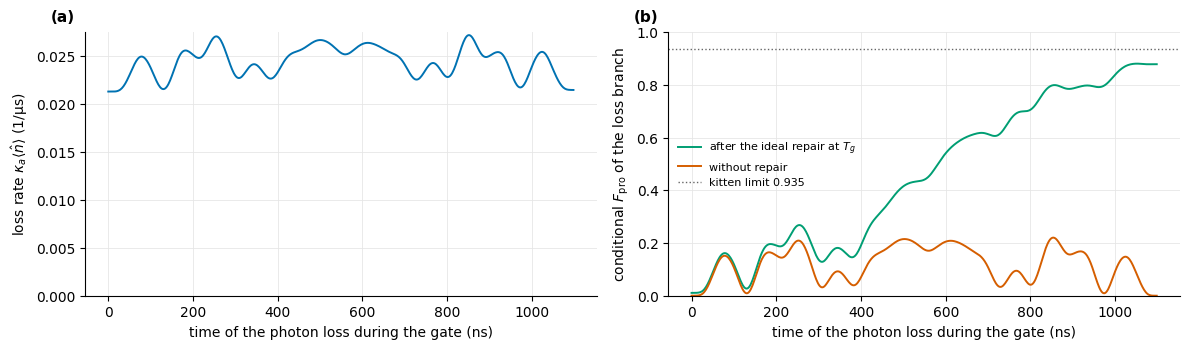

In [4]:
f_rep_mean = np.sum(loss_prof["p"] * loss_prof["f_repaired"]) / tot
f_none_mean = np.sum(loss_prof["p"] * loss_prof["f_unrepaired"]) / tot
late = loss_prof["t"] >= 1.0
f_late = np.sum(loss_prof["p"][late] * loss_prof["f_repaired"][late]) / loss_prof["p"][late].sum()
print(f"expected photon losses per gate (first order): {tot:.4f}")
print(f"average over all losses: F after ideal repair {f_rep_mean:.3f}, without {f_none_mean:.3f}")
print(f"kitten limit (a loss right after a perfect gate, best ideal repair): {F_KITTEN:.4f}")
print(f"if every loss were as repairable as those in the last 0.1 μs ({f_late:.3f}): gain "
      f"{tot * (f_late - f_none_mean):.4f} instead of {tot * (f_rep_mean - f_none_mean):.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
t_ns = loss_prof["t"] * 1e3
axes[0].plot(t_ns, loss_prof["p"] / DT, color=OKABE[0], lw=1.4)
axes[0].set_ylabel(r"loss rate $\kappa_a\langle\hat n\rangle$ (1/μs)")
axes[1].plot(t_ns, loss_prof["f_repaired"], color=OKABE[2], lw=1.4, label="after the ideal repair at $T_g$")
axes[1].plot(t_ns, loss_prof["f_unrepaired"], color=OKABE[4], lw=1.4, label="without repair")
axes[1].axhline(F_KITTEN, color="0.4", ls=":", lw=1, label="kitten limit 0.935")
axes[1].set_ylabel("conditional $F_{\\rm pro}$ of the loss branch")
axes[1].set_ylim(0, 1)
axes[1].legend(fontsize=8, frameon=False, loc="center left")
for ax in axes:
    ax.set_xlabel("time of the photon loss during the gate (ns)")
    tidy(ax)
axes[0].set_ylim(bottom=0)
for ax, k in zip(axes, "ab"):
    panel(ax, k)
fig.tight_layout()
fig.savefig("figures/fwm_tails_loss_timing.png", dpi=150)
plt.show()

**Figure 1. When d2 loses photons, and how well each loss can be repaired.** (a) The photon-loss rate during the
gate. (b) Conditional $F_{\rm pro}$ at $T_g$ of a branch with one loss at time $t$, with (green) and without
(vermilion) the ideal repair. Dotted: the kitten limit.
*Symbols:* $\kappa_a\langle\hat n\rangle$ = loss rate (losses per μs); kitten limit = 0.935, the best repair of a loss
right after a perfect gate.

**What it shows.** Late losses can be repaired; early ones cannot, because the rest of the gate scrambles them.

- A loss in the last 0.1 μs is repaired to 0.87, one in the first 0.4 μs only to 0.10–0.19. On average a repaired
  loss scores 0.46, against 0.12 unrepaired: that is Table 1's +0.92 %.
- Even a loss right after a perfect gate repairs only to 0.935, the *kitten limit*. A loss turns
  $(|1\rangle + |5\rangle)/\sqrt2$ into $(|0\rangle + \sqrt5|4\rangle)/\sqrt6$; adding the photon back gives
  $(|1\rangle + \sqrt5|5\rangle)/\sqrt6$, not the code word. No comb waveform can change the $1:\sqrt5$ ratio.
- The bigger lever is the gate. If every loss were as repairable as a late one, the same repair would gain about twice
  as much (0.020 instead of 0.009, printed). §3 tests this.

## 2.3 The cost of the tail's own time

With no pumps at all: d2 followed by an idle tail. The rows separate the Kerr phase (the closed system, where only the
Kerr and $\chi'$ terms act), photon loss alone, and every decay channel with the Kerr and $\chi'$ terms switched off in
the tail.

In [5]:
T2, W2 = ft.tail_targets(N_C, 2)
idle_rows = {}
for label, keep, hot in [("all decay", None, True), ("closed (Kerr and chi' only)", set(), True),
                         ("photon loss only", {"a"}, True),
                         ("all decay, Kerr and chi' off in the tail", None, False)]:
    tm = ft.tail_model(N_C, 2, include_higher_order=hot, keep=keep)
    R = ft.d2_output(N_C, 2, keep)
    row = {"0 (gate alone)": ft.fidelity_from_outputs(R, T2, W2)}
    n_prev = 0
    for T in TAIL_LENGTHS:                      # eta = 0 is time independent: chain the segments
        n = ft.n_steps(T)
        R, _ = ft.propagate(tm, np.zeros((n - n_prev, 2)), R)
        n_prev = n
        row[f"{T:g} μs"] = ft.fidelity_from_outputs(R, T2, W2)
    idle_rows[label] = row
idle = pd.DataFrame(idle_rows).T
display(idle.style.format("{:.5f}")
        .set_caption("Table 3. The d2 gate followed by an idle tail"))
KERR_PHASE = {n: -(dev.K_a / 2) * n * (n - 1) for n in (1, 3, 5)}       # rad/us, transmon in g
print("Kerr phase per μs on |1>, |3>, |5> (rad):", {n: round(v, 4) + 0.0 for n, v in KERR_PHASE.items()})
dphi = abs(KERR_PHASE[5] - KERR_PHASE[1])
print(f"relative phase |5> vs |1>: {dphi * ft.TAIL_US:.3f} rad after {ft.TAIL_US:g} μs, "
      f"{dphi * 3:.3f} rad after 3 μs")

,0 (gate alone),0.5 μs,1 μs,2 μs,3 μs
all decay,0.95555,0.94363,0.92917,0.89318,0.84879
closed (Kerr and chi' only),0.99107,0.98960,0.98525,0.96808,0.94005
photon loss only,0.96711,0.95503,0.94038,0.90394,0.85898
"all decay, Kerr and chi' off in the tail",0.95555,0.94507,0.93471,0.91438,0.89453


Kerr phase per μs on |1>, |3>, |5> (rad): {1: 0.0, 3: -0.0622, 5: -0.2073}
relative phase |5> vs |1>: 0.207 rad after 1 μs, 0.622 rad after 3 μs


**Table 3. The d2 gate followed by an idle tail (no pumps).** Columns: the length of the idle tail.
*Symbols:* $F_{\rm pro}$ at the end of the tail; $\chi'$ = the second-order dispersive shift; $n_c = 16$, two readout
levels.

**What it shows.** Waiting is expensive: the default 1 μs costs 2.6 % (0.9556 → 0.9292), and 3 μs costs 10.7 %.

- The Kerr phase alone (closed row) costs 0.6 % after 1 μs and 5.1 % after 3 μs; it grows roughly with the square of
  the time, as $|5\rangle$ turns against $|1\rangle$ by 0.21 rad per μs (printed). With no free rotation allowed, the
  tail must cancel this phase itself.
- Photon loss adds about 2.1 % per μs (photon-loss row minus closed row at 1 μs), close to $\bar n\kappa_a$ = 2.2 %:
  an unrepaired loss in the tail costs its whole branch.
- With Kerr off in the tail, all decay costs 6.1 % over 3 μs. Kerr and decay together would make 11.2 %, a little
  more than the 10.7 % measured with both on: the two costs overlap.

## 2.4 An estimate, recorded before training

A rough upper estimate of what an optimized tail of length $T$ gains over the gate alone:

$$
\Delta F \lesssim \underbrace{G}_{\text{the gate's losses repaired}}
- \underbrace{\bar n\kappa_a\,\min(T, \tau)}_{\text{losses too late to repair}}
- \underbrace{\bar n\kappa_a\,(T - \tau)_+\,(1 - 0.935)}_{\text{repaired losses, kitten limit}} .
$$

- $G$ is the ideal-repair gain of Table 1: the gate's own losses, repaired.
- Losses in the last $\tau$ of the tail come too late to repair and cost their whole branch (Table 3 supports this).
- Losses before that are repaired, but only to the kitten limit 0.935. $(x)_+$ means $x$ if positive, else 0.
- $\tau \approx 0.3$ μs is the shortest time a repair can take: telling even from odd photon numbers takes about
  $\pi/\chi_{gf} = 0.24$ μs, plus a comb-2 swap.

The estimate is **optimistic**. It assumes the Kerr phase is cancelled exactly and that repairs are perfect once
started. It ignores transmon decay, dephasing and losses during a repair. §6.5 compares it with the trained result.

In [6]:
est_rows = []
for T in TAIL_LENGTHS:
    gain, late, rep, total = tail_estimate(GAIN_IDEAL, T)
    est_rows.append({"tail (μs)": T, "gate's losses repaired": gain, "losses too late": late,
                     "repaired losses (kitten limit)": rep, "estimate vs gate alone": total})
cols = [k for k in est_rows[0] if k != "tail (μs)"]
display(pd.DataFrame(est_rows).style.hide(axis="index").format({**{c: "{:+.2%}" for c in cols}, "tail (μs)": "{:g}"})
        .set_caption("Table 4. Rough upper estimate of a tail's gain over d2 alone"))

tail (μs),gate's losses repaired,losses too late,repaired losses (kitten limit),estimate vs gate alone
0.5,+0.96%,-0.66%,-0.03%,+0.27%
1,+0.96%,-0.66%,-0.10%,+0.20%
2,+0.96%,-0.66%,-0.24%,+0.06%
3,+0.96%,-0.66%,-0.39%,-0.08%


**Table 4. Rough upper estimate of a tail's gain over d2 alone.** The last column is the sum of the three before it.
*Symbols:* the three terms of the formula above, in % of $F_{\rm pro}$.

**What it shows.** Even a perfect tail after d2 gains little: about +0.3 % at 0.5 μs, +0.2 % at 1 μs and −0.1 % at
3 μs.

- At 3 μs, late losses and the kitten-limit cost eat the whole repair gain. This is why the default tail is 1 μs.
- Every value stays below the +0.3 % go bar, the threshold `fwm_grape.ipynb` set before its own runs. After d2 a tail
  is unlikely to pass; §3 looks for a gate that leaves more to repair.
- Against "gate + the same idle time" (Table 3), any working tail would look large, because it also cancels the costs
  of its own time. The decision is always against the gate alone.

# 3. A gate that keeps losses repairable

A tail can only repair what the gate leaves repairable (§2.2). This section asks whether a different gate leaves more.

## 3.1 The problem: d2 scrambles losses

A tail repairs a photon loss by adding the photon back. That works only if, at $T_g$, the loss branch holds the right
answer with one photon missing: an error word. d2 was trained only to land the code words. After a loss mid-gate, the
rest of the pulse acts on error words it never saw in training, and scrambles them.

## 3.2 The fix: an error-semitransparent (EsT) gate

An EsT gate (Roy, Wetherbee & Fatemi, arXiv:2603.15356; `EST/`) is trained with one more goal: at every moment, the
error words move the way the code words move. A photon lost at any time then ends as the right answer minus one
photon, which a tail can repair as well as a loss right after the gate (up to the kitten limit).

Two caveats:

- **The EsT gate alone need not be better.** It is trained without loss and may use more photons or excite the
  transmon more. The claim is about gate + tail.
- **It is only *semi*-transparent.** The storage Kerr term acts differently on code and error words, and no drive can
  undo that.

## 3.3 Three measures of transparency

From the paper's Eqs. 6–8 (`EST/diagnostics.py`), computed on the lossless trajectories. Each is 0 for a perfectly
transparent gate.

| measure | what it asks | range |
|---|---|---|
| $\Delta_{\rm QEC}(t)$ | Could the moving code words still be corrected after one photon loss? It measures how far they break the Knill–Laflamme conditions (the standard test for a correctable error) for the errors $\{\hat 1, \hat a\}$. | 0 = correctable |
| $L(t)$ | How much of the moving error state has left the error space ${\rm span}\{\hat a\lvert 0_L(t)\rangle, \hat a\lvert 1_L(t)\rangle\}$? | 0 to 1 |
| $\eta_{\rm ET}(t)$ | How far has the error state's logical content (its Bloch vector) drifted from the code state's? Averaged over six logical states. | 0 to 2 |

EST calls the last one $\eta(t)$; it is written $\eta_{\rm ET}$ here to keep it apart from the comb waveforms
$\eta_c(t)$. The training logs also report $F_{\rm ET}$, EST's *error-transparency fidelity* (1 = the error state follows
the code state perfectly).

## 3.4 How the two closed-trained gates were trained

Code: `DGRAPE/est_gate.py` (cost and measures) and `DGRAPE/train_est_gate.py` (training).

- **Shared with d2:** chip, code, duration (1.1 μs), 2 ns steps, drive limits (bands ±27/±33 MHz, 48 ns ramp, cap
  25 rad/μs, box 25) and the seed-42 start. Only the cost differs.
- **EsT gate:** EST's cost in the closed system, $n_c = 20$, two stages of 2000 iterations. Weights (fidelity,
  transparency, even speed, drive cap): stage 1 (1, 0.7, 7, 1) builds transparency; stage 2 (1, 0.1, 0, 1) closes the
  gate.
- **Ord gate (the control):** the same two stages with the transparency and speed weights set to 0.
- **Scoring:** all three gates in the open system with the decay set (the model d2 was trained in), at
  **$n_c = 24$**. The closed-trained gates reach photon number 15–17, and at $n_c = 16$ their closed fidelity reads up
  to 0.016 low. $n_c = 28$ is the held-out check. d2 gives the same numbers at every $n_c$.
- **EST's tiers** (printed below): *closed* (F1 ≥ 0.999), *open* (the pulse drives, but F1 < 0.999) and *parked*
  (it barely drives). These names have nothing to do with the open or closed *system*.

```
python3 DGRAPE/train_est_gate.py --variant est --maxiter 2000     # tag X_est_closed
python3 DGRAPE/train_est_gate.py --variant ord --maxiter 2000     # tag X_ord_closed
```

X_ord_closed: after stage 1 F1 0.9997, F_ET 0.331; after stage 2 F1 0.99987, F_ET 0.331 (tier: closed); max |eps| 25.0 / 25.0 rad/μs; 2.0% of x at the box; 28 min
   closed F1 by n_c: {'16': 0.98406, '18': 0.99883, '20': 0.99987, '24': 0.99981, '28': 0.99981}
X_est_closed: after stage 1 F1 0.4880, F_ET 0.953; after stage 2 F1 0.99782, F_ET 0.726 (tier: open); max |eps| 25.0 / 25.0 rad/μs; 0.2% of x at the box; 28 min
   closed F1 by n_c: {'16': 0.99207, '18': 0.99689, '20': 0.99782, '24': 0.99788, '28': 0.99788}
EsT at seed 43 (not used, seed 42 kept): F1 0.9985, F_ET 0.774 (tier: open)
EsT at seed 44 (not used, seed 42 kept): F1 0.3312, F_ET 1.000 (tier: parked)


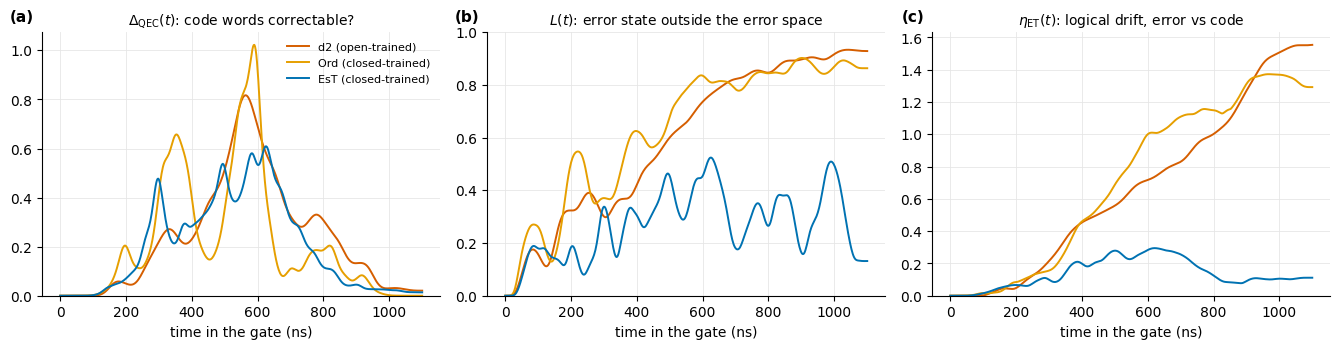

In [7]:
GATES = {"d2 (open-trained)": ft.d2_pulse(),
         "Ord (closed-trained)": np.load("pulses/dgrape/u_X_ord_closed.npy"),
         "EsT (closed-trained)": np.load("pulses/dgrape/u_X_est_closed.npy")}
COLORS = {"d2 (open-trained)": OKABE[4], "Ord (closed-trained)": OKABE[1], "EsT (closed-trained)": OKABE[0]}
for tag in ("X_ord_closed", "X_est_closed"):
    info = json.load(open(f"pulses/dgrape/{tag}.json"))
    s1, s2 = (st["end"] for st in info["stages"])
    print(f"{tag}: after stage 1 F1 {s1['F1']:.4f}, F_ET {s1['F_ET']:.3f}; after stage 2 F1 {s2['F1']:.5f}, "
          f"F_ET {s2['F_ET']:.3f} (tier: {info['tier']}); max |eps| {info['max_drive_modulus']['cav']:.1f} / "
          f"{info['max_drive_modulus']['tra']:.1f} rad/μs; {info['frac_preimage_pinned']:.1%} of x at the box; "
          f"{info['wall_s'] / 60:.0f} min")
    print("   closed F1 by n_c:", {k: round(v, 5) for k, v in info["trunc_scan"].items()})
for seed in (43, 44):
    info = json.load(open(f"pulses/dgrape/X_est_closed_s{seed}.json"))
    print(f"EsT at seed {seed} (not used, seed 42 kept): F1 {info['F1']:.4f}, F_ET {info['F_ET']:.3f} "
          f"(tier: {info['tier']})")

et = {name: eg.metrics(u, N_CMP) for name, u in GATES.items()}   # closed trajectories
fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.6))
for name, m in et.items():
    for ax, key in zip(axes, ("delta_qec", "leakage", "eta_avg")):
        ax.plot(m["t"] * 1e3, m[key], color=COLORS[name], lw=1.4, label=name)
for ax, lab in zip(axes, (r"$\Delta_{\rm QEC}(t)$: code words correctable?",
                          r"$L(t)$: error state outside the error space",
                          r"$\eta_{\rm ET}(t)$: logical drift, error vs code")):
    ax.set_xlabel("time in the gate (ns)")
    ax.set_title(lab, fontsize=10)
    ax.set_ylim(bottom=0)
    tidy(ax)
axes[1].set_ylim(0, 1)
for ax, k in zip(axes, "abc"):
    panel(ax, k)
axes[0].legend(fontsize=8, frameon=False)
fig.tight_layout()
fig.savefig("figures/fwm_tails_et_metrics.png", dpi=150)
plt.show()

**Figure 2. How transparent each gate is over time.** (a) $\Delta_{\rm QEC}$, (b) $L$ and (c) $\eta_{\rm ET}$,
computed on the lossless trajectories at $n_c = 24$. Lower is more transparent.
*Symbols:* the three measures of §3.3. §3.5 discusses the figure.

In [8]:
B24 = embedded_basis(N_CMP, 1)
_, T24, W24 = process_targets("X", N_CMP, 1)
N_T = ft.n_steps(ft.TAIL_US)                               # the default tail
eta_teeth = ft.eta_from_teeth(fwm.beta_table2(ft.REPAIR_PATHS), N_T, DT, N_CMP)
cmp_rows = []
for name, u in GATES.items():
    s = eg.summary(et[name])
    scan = eg.truncation_scan(u)
    R1 = ft.gate_output(u, N_CMP, 1)                       # decay set, readout cut to one level (exact)
    F_alone = ft.fidelity_from_outputs(R1, T24, W24)
    rep = ft.ideal_repair_fidelity(R1, T24, W24, N_CMP, 1)
    opt = ft.optimal_recovery_fidelity(R1, B24)
    ph = ft.ideal_repair_fidelity(ft.gate_output(u, N_CMP, 1, {"a"}), T24, W24, N_CMP, 1)["phases"]
    gate_prof = ft.loss_time_profile(ph, N_CMP, pulse=u)
    p = gate_prof["p"]
    sc = lambda eta, **kw: ft.score(eta, pulse=u, **{"n_c": N_CMP, **kw})["F_pro"]    # noqa: E731
    vals = [
        ("closed (no loss)", "closed fidelity F1, six states", s["F1"], "{:.5f}"),
        ("closed (no loss)", "F1 at n_c 24 minus F1 at n_c 16", scan[24] - scan[16], "{:+.1e}"),
        ("closed (no loss)", "highest photon level used", s["max_active_fock"], "{:.0f}"),
        ("closed (no loss)", "mean Δ_QEC", s["delta_qec_mean"], "{:.3f}"),
        ("closed (no loss)", "mean L", s["leakage_mean"], "{:.3f}"),
        ("closed (no loss)", "L at the end of the gate", s["leakage_T"], "{:.3f}"),
        ("closed (no loss)", "mean η_ET", s["eta_mean"], "{:.3f}"),
        ("open, gate alone", "F_pro, decay set", F_alone, "{:.5f}"),
        ("open, gate alone", "F_pro, n_c 28 (held out)", sc(np.zeros((0, 2)), n_c=28), "{:.5f}"),
        ("open, gate alone", "F_pro, all channels", sc(np.zeros((0, 2)), dephasing=True, heating=True), "{:.5f}"),
        ("open, gate alone", "photon losses per gate", p.sum(), "{:.4f}"),
        ("open, with a tail", "a loss during the gate, after the ideal repair",
         np.sum(p * gate_prof["f_repaired"]) / p.sum(), "{:.3f}"),
        ("open, with a tail", "+ ideal repair at T_g", rep["F"], "{:.5f}"),
        ("open, with a tail", "gain of the ideal repair", rep["F"] - F_alone, "{:+.2%}"),
        ("open, with a tail", "+ best recovery of any kind", opt["F_opt"], "{:.5f}"),
        ("open, with a tail", f"+ idle tail, {ft.TAIL_US:g} μs", sc(np.zeros((N_T, 2))), "{:.5f}"),
        ("open, with a tail", f"+ Table II teeth, {ft.TAIL_US:g} μs", sc(eta_teeth), "{:.5f}"),
    ]
    cmp_rows.append((name, vals))
idx = pd.MultiIndex.from_tuples([(g, k) for g, k, _, _ in cmp_rows[0][1]])
cmp_txt = pd.DataFrame({name: [f.format(v) for _, _, v, f in vals] for name, vals in cmp_rows}, index=idx)
display(cmp_txt.style.set_caption("Table 5. The three gates compared"))

**Table 5. The three gates compared.** Upper block: transparency, in the closed system. Middle: the gate alone in the
open system. Lower: what a tail could add after each gate. $n_c = 24$ unless stated.
*Symbols:* F1 = closed fidelity over six states; $\Delta_{\rm QEC}$, $L$, $\eta_{\rm ET}$ = the measures of §3.3;
$F_{\rm pro}$ with the decay set unless "all channels"; "a loss during the gate, after the ideal repair" = the average
conditional $F_{\rm pro}$ of a single-loss branch, as in Figure 1b.

In [9]:
# Section 2.4's estimate after each gate, with that gate's ideal-repair gain
gate_est = {name: {f"{T:g} μs": tail_estimate({k: v for _, k, v, _ in vals}["gain of the ideal repair"], T)[3]
                   for T in TAIL_LENGTHS}
            for name, vals in cmp_rows}
display(pd.DataFrame(gate_est).T.style.format("{:+.2%}")
        .set_caption("Table 6. Rough upper estimate of a tail's gain, after each gate"))

,0.5 μs,1 μs,2 μs,3 μs
d2 (open-trained),+0.27%,+0.20%,+0.06%,-0.08%
Ord (closed-trained),+0.38%,+0.31%,+0.16%,+0.02%
EsT (closed-trained),+1.16%,+1.09%,+0.95%,+0.80%


**Table 6. Rough upper estimate (§2.4) of a tail's gain, after each gate,** using each gate's own ideal-repair
gain $G$ from Table 5. Columns: tail length.
*Symbols:* each entry is the estimated change in $F_{\rm pro}$ against that gate alone.

## 3.5 What the comparison shows

**The EsT gate keeps losses repairable, and it is also the best gate on its own.**

*Training.*

- EsT stage 1 stalled at F1 0.488 with $F_{\rm ET}$ 0.953: a pulse that barely drives is trivially transparent. Stage 2
  then closed the gate to F1 0.99782 while keeping $F_{\rm ET}$ at 0.726 (Ord: 0.331). That is just short of EST's
  0.999 bar, so its tier is *open*.
- Of two more seeds, seed 44 parked for good (F1 ≈ 1/3, no drive) and seed 43 behaved like seed 42 (Appendix B.3).
  Seed 42 is the one used.

*Transparency (Figure 2, Table 5).*

- With EsT the error state stays in the error space: mean $L$ is 0.27, against 0.59 (d2) and 0.63 (Ord), and at $T_g$
  0.13, against 0.93 and 0.86. Mean $\eta_{\rm ET}$ is 0.14, against 0.68 and 0.72.
- $\Delta_{\rm QEC}$ barely differs (0.20, against 0.24 and 0.22). EST's cost does not target it.

*Repairability (Table 5, lower block).*

- A loss during the EsT gate, ideally repaired at $T_g$, scores 0.861 on average, close to the kitten limit 0.935
  (d2: 0.461; Ord: 0.558).
- So the ideal repair gains about twice as much: +1.85 % after EsT, against +0.96 % (d2) and +1.07 % (Ord).

*The gate alone.*

- EsT alone scores 0.96803, above Ord (0.96380) and d2 (0.95556), and with all channels on as well (0.95594, 0.94945,
  0.94472). Each gate is a single training run, so read these gaps as indications, not measurements.
- Part of d2's deficit is its own 0.9 % coherent error (closed F1 0.99117). That Ord also beats it suggests d2's
  open-system training, which plateaued and was clipped, left fidelity behind.

*Fixed tails and the estimate.*

- A fixed 1 μs tail costs about 2.6 % (idle) or 3.0 % (Table II teeth) after every gate: the cost of the tail's time
  (§2.3) does not depend on the gate.
- With the larger repair gain, the §2.4 estimate after EsT is +1.09 % at 1 μs (Table 6), against +0.20 % after d2.
  This is why the training runs started with the EsT gate (§5).

*Caveat.* The best-recovery row is a lower bound, because its iterative search can stop early. For d2 it reads 0.98938
here and 0.98968 at $n_c = 16$ (Table 1), so read it to about $\pm 3\times10^{-4}$.

# 4. Method: the tail model

## 4.1 One waveform per comb

- **Pump displacement** $\beta$: the small, dimensionless complex amplitude by which a strong off-resonant pump shakes
  the transmon. $|\beta|^2$ is roughly the number of pump photons in the transmon. Expanding the junction energy to
  fourth order gives both the FWM couplings and the Stark shifts (`fwm_tuning.ipynb` §1).
- **Tooth** $(c, n)$ in `fwm_grape.ipynb`: a slow complex envelope $\beta_{c,n}(t)$ on a fixed carrier frequency
  $\Delta_{c,n}$ (about ±140 MHz in the DGRAPE frame).
- **Comb displacement** $\xi_c(t) = \sum_n \beta_{c,n}(t)\,e^{i\Delta_{c,n}t}$: everything comb $c$ does at time $t$.
  The Hamiltonian sees $g_c\xi_c\hat A_c + {\rm h.c.}$ with $\hat A_1 = \hat a^\dagger\hat q^{\dagger 2}$ (add a storage
  photon, lift the transmon $g \to f$) and $\hat A_2 = \hat q^2\hat r^\dagger$ (lower the transmon $f \to g$, add a
  readout photon), plus the Stark term $-(|\xi_1|^2 + |\xi_2|^2)\hat S$. Here $\hat a$, $\hat q$, $\hat r$ lower the
  storage, transmon and readout, and $g_c$ is the coupling of comb $c$.
- **The comb waveform** $\eta_c(t)$, this notebook's control: the same comb seen from one reference tooth,

$$
\xi_1(t) = \eta_1(t)\,e^{+i\Delta_{\rm ref}t}, \qquad \xi_2(t) = \eta_2(t)\,e^{-i\Delta_{\rm ref}t},
\qquad \Delta_{\rm ref} = \Delta_{1,3},
$$

with $t$ counted from the start of the tail; $\Delta_{1,3}$ is the carrier of comb 1's tooth $n = 3$. Since
$|\eta_c| = |\xi_c|$, the cap $|\eta_c| \le 0.1$ is `fwm_grape`'s comb cap. In the lab, comb 1 is one waveform played
around $\omega_a + \omega_{gf} - 3\chi_{gf}$, and comb 2 around $\omega_r - \omega_{gf} + 3\chi_{gf}$.

## 4.2 The rotating frame, and why it is exact

DGRAPE's frame turns every mode at its linear frequency, so $|f\rangle$ sits at $-\alpha$ (the transmon is
nonlinear). The tail adds one more rotation, of $|f\rangle$ only, by $\Delta_{\rm ref} \approx \alpha + 3\chi_{gf}$:
$\hat\rho' = \hat V^\dagger\hat\rho\hat V$ with $\hat V = e^{i\Delta_{\rm ref}t\hat P_f}$, where $\hat P_f$ projects on
$|f\rangle$. Then

$$
\hat H' = \hat H_d + \Delta_{\rm ref}\hat P_f + \big(\eta_1 g_1\hat A_1 + \eta_2 g_2\hat A_2 + {\rm h.c.}\big)
- \big(|\eta_1|^2 + |\eta_2|^2\big)\hat S \;\big[+\,\eta_1\eta_2\hat M + {\rm h.c.}\big],
$$

with $\hat H_d$ the drift Hamiltonian. The bracketed pump-mixing term is used only in held-out scoring.

- $\hat A_1$ raises $g \to f$ and picks up a phase from $\hat V$ that cancels comb 1's carrier; $\hat A_2$ lowers
  $f \to g$, and the opposite phase cancels comb 2's.
- $\hat H_d$, $\hat S$ and the pump-mixing operator $\hat M = \hat a^\dagger\hat r^\dagger$ have no off-diagonal
  elements on $|f\rangle$, so they are unchanged.
- The jump operators $\hat a$, $\hat r$ and $|g\rangle\langle e|$ commute with $\hat P_f$; $|e\rangle\langle f|$ only
  gains an overall phase, which the dissipator ignores. So the Lindblad equation keeps its form.
- $\hat V = 1$ at the start of the tail, and every target has the transmon in $|g\rangle$, where $\hat V$ acts as 1. So
  $F_{\rm pro}$ is the same in both frames.

**Consequence.** With $\eta$ held constant over each 2 ns step, the generator is constant over the step, and one
matrix exponential per step is the exact solution. `fwm_grape` needed four exponentials per step (CF4, a fourth-order
scheme, with $S = 2$ sub-steps) because its carriers turned by 1.8 rad per step. This works only because the transmon
drive is off in the tail: its $e \to f$ element would turn at $\Delta_{\rm ref}$. The cavity drive does not touch
$|f\rangle$, so adding it later keeps the frame exact. Appendix A checks all of this numerically.

## 4.3 Where the teeth sit

In [10]:
off = ft.tooth_offsets(N_C, ft.N_REF, fwm.FULL_PATHS)
band = ft.ETA_BAND
tab = pd.DataFrame({
    "tooth n": off["paths"],
    "repair": [f"{n - 1} -> {n}" for n in off["paths"]],
    "starts from": ["error state (even n-1)" if n % 2 else "code word (odd n-1)" for n in off["paths"]],
    "comb 1 offset (MHz)": mhz(off["comb1"]),
    "comb 2 offset (MHz)": mhz(off["comb2"]),
})
tab["inside the band"] = [(band[0] < a < band[1]) and (band[0] < b < band[1])
                          for a, b in zip(tab["comb 1 offset (MHz)"], tab["comb 2 offset (MHz)"])]
display(tab.style.hide(axis="index").format({"comb 1 offset (MHz)": "{:+.3f}", "comb 2 offset (MHz)": "{:+.3f}"})
        .set_caption("Table 7. Where each tooth sits inside the comb waveforms"))
tm16 = ft.tail_model(N_C)
print(f"Delta_ref / 2pi = {mhz(tm16.delta_ref):.3f} MHz (alpha/2pi = {mhz(dev.alpha_q):.2f}, "
      f"3 chi_gf/2pi = {3 * mhz(dev.chi_gf):.2f})")
print(f"Stark shift of every comb-1 line at |eta_1| = 0.1: {mhz(4 * dev.alpha_q + dev.chi_ge) * 0.01:.2f} MHz; "
      f"comb-2 lines: {mhz(4 * dev.alpha_q - dev.chi_qr) * 0.01:.2f} MHz")
print(f"drift spread (half width) of the tail model: {mhz(tm16.model.half_width_d):.1f} MHz, "
      f"DGRAPE frame: {mhz(Model(N_C, 2, include_higher_order=True).half_width_d):.1f} MHz")

tooth n,repair,starts from,comb 1 offset (MHz),comb 2 offset (MHz),inside the band
1,0 -> 1,error state (even n-1),-4.135,+4.135,True
2,1 -> 2,code word (odd n-1),-2.066,+2.069,True
3,2 -> 3,error state (even n-1),+0.000,+0.007,True
4,3 -> 4,code word (odd n-1),+2.062,-2.052,True
5,4 -> 5,error state (even n-1),+4.120,-4.107,True
6,5 -> 6,code word (odd n-1),+6.174,-6.158,True
7,6 -> 7,error state (even n-1),+8.225,-8.205,True
8,7 -> 8,code word (odd n-1),+10.271,-10.248,True
9,8 -> 9,error state (even n-1),+12.314,-12.288,False


Delta_ref / 2pi = 140.485 MHz (alpha/2pi = 134.28, 3 chi_gf/2pi = 6.21)
Stark shift of every comb-1 line at |eta_1| = 0.1: 5.38 MHz; comb-2 lines: 5.36 MHz
drift spread (half width) of the tail model: 15.5 MHz, DGRAPE frame: 82.6 MHz


**Table 7. Where each tooth sits inside the comb waveforms.** Frequencies are offsets inside $\eta_c$, measured from
the reference tooth $n = 3$.
*Symbols:* tooth $n$ drives $n{-}1 \to n$ photons; "starts from" says whether the photon number before the repair is
an error state (even) or a code word (odd); "inside the band" = within the ±12 MHz filter on $\eta_c$.

**What it shows.** Each comb is a ladder with one rung per photon number, 2.06 MHz apart.

- In comb 1 the repair teeth $n = 1, 3, 5$ sit at about −4.1, 0 and +4.1 MHz; comb 2 is almost its mirror image.
  Between them sit teeth that start from a code word and would pump it out. A band filter cannot exclude them; the
  waveform has to avoid them.
- The Stark shift moves all teeth of a comb together, by 5.4 MHz at the cap (printed). Following it takes one phase
  ramp on $\eta_c$, and the ±12 MHz band leaves room for that.
- The tail's drift spans only ±15.5 MHz, against ±82.6 MHz in the DGRAPE frame, which keeps the one exponential per
  step cheap (Appendix A.2).

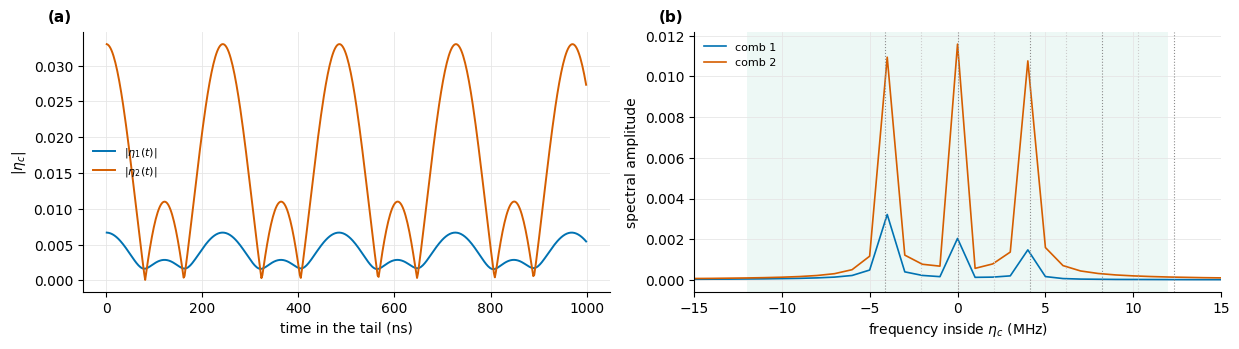

In [11]:
lib = ft.start_library(ft.TAIL_US, n_c=N_C)
eta_t2 = lib["tableII"]
N_T = eta_t2.shape[0]
t_us = (np.arange(N_T) + 0.5) * DT
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.6))
show = t_us <= 1.0                                          # at most the first us
for c, col in ((0, OKABE[0]), (1, OKABE[4])):
    axes[0].plot(t_us[show] * 1e3, np.abs(eta_t2[show, c]), color=col, lw=1.4, label=fr"$|\eta_{c + 1}(t)|$")
axes[0].set_xlabel("time in the tail (ns)")
axes[0].set_ylabel(r"$|\eta_c|$")
axes[0].legend(fontsize=8, frameon=False)
freq = np.fft.fftshift(np.fft.fftfreq(N_T, DT))             # MHz
for c, col in ((0, OKABE[0]), (1, OKABE[4])):
    spec = np.abs(np.fft.fftshift(np.fft.fft(eta_t2[:, c]))) / N_T
    axes[1].plot(freq, spec, color=col, lw=1.2, label=f"comb {c + 1}")
for n, x1 in zip(off["paths"], mhz(off["comb1"])):
    axes[1].axvline(x1, color="0.8" if n % 2 == 0 else "0.55", lw=0.8, ls=":")
axes[1].axvspan(band[0], band[1], color=OKABE[2], alpha=0.07, lw=0)
axes[1].set_xlim(-15, 15)
axes[1].set_xlabel("frequency inside $\\eta_c$ (MHz)")
axes[1].set_ylabel("spectral amplitude")
axes[1].legend(fontsize=8, frameon=False)
for ax, k in zip(axes, "ab"):
    tidy(ax)
    panel(ax, k)
fig.tight_layout()
fig.savefig("figures/fwm_tails_tableII_waveform.png", dpi=150)
plt.show()

**Figure 3. Shirol's Table II teeth written as one waveform per comb.** (a) $|\eta_c(t)|$ over the default 1 μs
tail. (b) Its spectrum (1 MHz resolution). Dotted lines: the comb-1 teeth (darker for the repair teeth, $n$ odd).
Green: the ±12 MHz band.
*Symbols:* $\eta_1$, $\eta_2$ = the comb-1 and comb-2 waveforms.

**What it shows.** A comb of fixed teeth is a pulse train.

- The three repair teeth, 4.13 MHz apart, beat with a period of 242 ns.
- The comb-2 teeth are the strong ones in Table II ($\beta = 0.011$ each, so $|\eta_2|$ reaches 0.033).
- A firmer limit applies to any waveform, trained or not: telling neighbouring photon numbers apart takes about
  $\pi/\chi_{gf} = 0.24$ μs, so one repair cannot be much faster than that. The trained tails of §6 take about
  600 ns.

## 4.4 Controls and constraints

| control | shape | meaning | hard limit | soft limit (penalty) | filtering |
|---|---|---|---|---|---|
| $\eta$ | $(N, 4)$ real: $\eta_1^I, \eta_1^Q, \eta_2^I, \eta_2^Q$ | one complex waveform per comb, $\eta = \eta^I - i\eta^Q$ | box $\lvert x\rvert \le 25$ on the pre-image, $x = 250\,\eta$ | $\sum_{t,c}(\lvert\eta_c(t)\rvert - 0.1)_+^2$; derivative | band ±12 MHz on each $\eta_c$, 48 ns ramp at both ends |

- **One cap does the job of two.** `fwm_grape` capped every tooth and, separately, every comb. Here only the comb
  waveform exists, and $|\eta_c|$ is constant over a step, so the cap is checked exactly at every step.
- **The band** is symmetric, so the sign convention $\eta = \eta^I - i\eta^Q$ does not matter. It holds the repair
  teeth (±4.1 MHz), the Stark shift at the cap (5.4 MHz) and a margin.
- **The ramp** brings the waveform smoothly to zero at both ends of the tail.
- **Weights** are `fwm_grape`'s and are not tuned: amplitude 5.0, derivative 0.625 (the gate recipe's weights times
  $250^2$, because $x = 250\,\eta$).
- The chain (band filter, then ramp) is `fwm.BetaChain` with two tones, which is exactly one
  `core.ramp.make_constraint_chain` block.

In [12]:
N_tail = ft.n_steps(ft.TAIL_US)
bins = int(make_band_mask(N_tail, DT, *ft.ETA_BAND).sum())
print(f"{ft.TAIL_US:g} μs tail: N = {N_tail} steps, frequency spacing {1 / ft.TAIL_US:.2f} MHz, the band keeps {bins} bins per comb "
      f"-> {2 * bins * 2} real degrees of freedom")
print("penalty weights:", {k: round(v, 4) for k, v in ft.TAIL_PENALTIES.items()}, f"  scale x = {ft.S_ETA:.0f} eta")

1 μs tail: N = 500 steps, frequency spacing 1.00 MHz, the band keeps 25 bins per comb -> 100 real degrees of freedom
penalty weights: {'amp': 5.0, 'deriv': 0.625, 'forbid': 0.0, 'transmon': 0.0}   scale x = 250 eta


## 4.5 The cost function and the fixed baselines

$$
C(x) = 1 - F_{\rm pro}\big(\text{gate} + \text{tail}(\eta)\big)
+ \lambda_{a}\sum_{t,c}\big(|\eta_c(t)| - 0.1\big)_+^2
+ \lambda_{d}\sum_{t}|\eta(t + dt) - \eta(t)|^2,
\qquad \eta = \frac{\text{ramp}(\text{band}(x))}{250},
$$

$$
F_{\rm pro} = \frac14\sum_b w_b\,{\rm Re}\,{\rm Tr}\Big[\big(\hat T_b \otimes \mathbb 1_r\big)^\dagger\,
\Phi_{\rm tail}\big(\Phi_{\rm gate}(\hat E_b)\big)\Big], \qquad w = (1, 1, 2).
$$

- $\lambda_a$, $\lambda_d$ are the amplitude and derivative weights of §4.4.
- $\hat E_b$ are the three process inputs $|0_L\rangle\langle 0_L|$, $|1_L\rangle\langle 1_L|$ and
  $|0_L\rangle\langle 1_L|$, with weights $w_b$. $\hat T_b$ is the **ideal X** applied to each, with the transmon in
  $|g\rangle$. There is no free rotation: no storage frame update, no virtual Z.
- The readout is **traced out** at the end ($\otimes\mathbb 1_r$): a readout photon still there is the dumped error, not
  a mistake. $\langle\hat n_r\rangle$ at the end is reported for every pulse, and `score` also gives the stricter
  "readout empty" fidelity.
- $\Phi_{\rm gate}(\hat E_b)$ is the gate's output, computed once (`ft.gate_output`; `ft.d2_output` for d2). Training
  propagates only the tail.

The fixed baselines, at each tail length after d2: the gate alone; gate + idle tail; and gate + Shirol's Table II teeth
held on for the whole tail (PReSPA as published, written as $\eta$).

In [13]:
base = pd.DataFrame(ft.baselines(TAIL_LENGTHS, N_C, label="gate")).rename(columns={"change_vs_d2": "change_vs_gate"})
display(base.rename(columns={"tail_us": "tail (μs)", "change_vs_gate": "change vs d2 alone"})
        .style.hide(axis="index").format({"tail (μs)": "{:g}", "F_pro": "{:.5f}", "change vs d2 alone": "{:+.2%}"})
        .set_caption("Table 8. Fixed tails after d2"))

case,tail (μs),F_pro,change vs d2 alone
gate alone,0,0.95555,+0.00%
gate + idle,0.5,0.94363,-1.19%
gate + Table II teeth,0.5,0.94194,-1.36%
gate + idle,1,0.92917,-2.64%
gate + Table II teeth,1,0.92545,-3.01%
gate + idle,2,0.89318,-6.24%
gate + Table II teeth,2,0.89231,-6.32%
gate + idle,3,0.84879,-10.68%
gate + Table II teeth,3,0.85332,-10.22%


**Table 8. Fixed tails after d2.** The idle tail has no pumps; "Table II teeth" holds Shirol's published teeth on for
the whole tail, without band filter or ramp.
*Symbols:* $F_{\rm pro}$ at the end of the tail; change = difference from d2 alone; $n_c = 16$, readout traced out.

In [14]:
chain = ft.eta_chain(N_tail)
start_rows = []
for name, eta in lib.items():
    eta_c = fwm.beta_from_real(chain.to_physical(ft.eta_preimage(eta)))     # as the optimizer will see it
    r = ft.score(eta_c, n_c=N_C)
    start_rows.append({"start": name, "F_pro": r["F_pro"], "change vs gate alone": r["F_pro"] - F_DISS,
                 "F (readout empty)": r["F_empty"], "⟨n_r⟩ at end": r["n_r_end"], "P_f at end": r["P_f_end"],
                 "max |eta_1|": r["max_eta_1"], "max |eta_2|": r["max_eta_2"]})
display(pd.DataFrame(start_rows).style.hide(axis="index")
        .format({"F_pro": "{:.5f}", "change vs gate alone": "{:+.2%}", "F (readout empty)": "{:.5f}",
                 "⟨n_r⟩ at end": "{:.1e}", "P_f at end": "{:.1e}", "max |eta_1|": "{:.3f}", "max |eta_2|": "{:.3f}"})
        .set_caption(f"Table 9. Candidate training starts, {ft.TAIL_US:g} μs tail after d2"))
F_t2_raw = base.query("case == 'gate + Table II teeth' and tail_us == @ft.TAIL_US")["F_pro"].item()
F_t2_chain = next(r["F_pro"] for r in start_rows if r["start"] == "tableII")
print(f"Table II teeth, {ft.TAIL_US:g} μs: raw (Table 8) {F_t2_raw:.5f}, through the band and ramp (Table 9) "
      f"{F_t2_chain:.5f} ({F_t2_chain - F_t2_raw:+.4f})")

start,F_pro,change vs gate alone,F (readout empty),⟨n_r⟩ at end,P_f at end,max |eta_1|,max |eta_2|
zero,0.92917,-2.64%,0.92917,0.0e+00,1.4e-08,0.000,0.000
tableII,0.92824,-2.73%,0.92808,3.9e-04,2.4e-03,0.007,0.033
tableII_x3,0.83247,-12.31%,0.83196,2.0e-02,5.2e-02,0.020,0.099
bursts_f0.5,0.81306,-14.25%,0.81260,2.6e-02,7.0e-02,0.049,0.074


Table II teeth, 1 μs: raw (Table 8) 0.92545, through the band and ramp (Table 9) 0.92824 (+0.0028)


**Table 9. The candidate training starts, 1 μs tail after d2,** each passed through the band filter and ramp, as the
optimizer sees it.
*Symbols:* `tableII` = the Table II teeth; `tableII_x3` = the same, three times stronger; `bursts_f0.5` = comb 1 then
comb 2 every 0.6 μs, at half the amplitude of a full swap; F (readout empty) = $F_{\rm pro}$ when the readout must also
end empty; ⟨$n_r$⟩, $P_f$ = readout photons and transmon-$f$ population at the end; max $|\eta_c|$ = the largest pump
amplitude.

**What Tables 8 and 9 show.** Every tail with real time in it starts below d2 alone, so the optimizer must climb from
below the baseline.

- The idle tail loses 1.2 % at 0.5 μs, 2.6 % at 1 μs and 10.7 % at 3 μs. The Table II teeth beat idling only at 3 μs
  (+0.45 %): held constant they need about 2.8 μs per correction (`fwm_grape.ipynb` Table 2), and they do nothing
  about the Kerr phase.
- Through the band filter and ramp the same teeth score 0.28 % higher (printed): switching them on and off gently
  helps.
- Stronger starts are much worse (−12 % and −14 %). They leave 5 % and 7 % of the population in $|f\rangle$. A likely
  cause, not tested: at these strengths a comb-1 tooth also drives its neighbours, which start from code words
  (Table 7).

# 5. Training, as run

The protocol was written before the runs (2026-10-20) and adjusted before they started (2026-10-21). This section gives
the version that was run. Machine, threads and wall-clock times are in Appendix B.2.

1. **Gates.** Tails were trained after all three gates: the EsT gate (the most to repair, §3), the Ord gate (its
   control) and d2.
2. **Lengths and starts.** Tails of 0.5, 1 and 2 μs. EsT and Ord tails started from the Table II teeth
   (`--start tableII`, tag `t2`) and from zero plus a little noise (`--start zero --noise 0.005 --seed 1`, tag `z`;
   5 % of the cap). d2 tails used the Table II start only. That makes 15 runs of 300 L-BFGS-B iterations.
3. **Variables:** the pre-image $x$, shape $(N, 4)$, with $N = 500$ steps for 1 μs. The gate is fixed.
4. **Truncation: the gate at $n_c = 24$, the tail at $n_c = 16$.** The closed-trained gates need $n_c = 24$ (§3.4),
   but the tail only needs the state the gate leaves behind. At $T_g$ at most $2\times10^{-5}$ of the population is at
   photon number 16 or above, so the trainer runs the gate at $n_c = 24$ and keeps photon numbers 0–15 for the tail
   (`--gate-n-c 24`; `fwm_tail.tail_input`, `cut_storage`). The population dropped (`trace_cut` in each run file) is
   $1.1\times10^{-5}$ for EsT and $1.3\times10^{-5}$ for Ord; the cut and uncut starting fidelities of the EsT 1 μs
   Table II tail agree to $3\times10^{-16}$.
5. **Settings:** two readout levels, decay set, higher-order terms on, readout traced out, cap 0.1, band ±12 MHz, 48 ns
   ramp, the weights of §4.4, L-BFGS-B with `gtol` $10^{-12}$, best-vs-final (the best point seen is kept if the last
   one is worse).
6. **Resumed runs.** Eight runs were still climbing at 300 iterations: every 1 μs run and the three 2 μs Table II runs.
   They ran 300 more iterations from their best pre-image (`--start xe_<tag>_best.npy`, tag `<tag>_r`); L-BFGS-B
   restarts without its curvature memory there. The 0.5 μs runs and the two 2 μs zero starts had stopped moving and
   were not resumed.
7. **Held-out scoring** (`DGRAPE/fwm_tail_score.py` → `tables/fwm_tail_heldout.csv`) of the gate alone, the idle tail,
   the Table II teeth and every trained tail: $n_c$ 24 and 28 for EsT and Ord (18 and 20 for d2), with gate and tail
   re-run without the cut; three readout levels; all channels (dephasing and heating in gate and tail); couplings
   $g/\sqrt2$; pump mixing $s$ = 1 and 2; Stark shift off; $\eta \times 0.9$ and $\times 1.1$; readout required empty.
   Also recorded: $\langle\hat n_r\rangle$, $P_e$, $P_f$ at the end, and the pump maxima.
8. **Go / no-go:** a gain of at least +0.3 % over *the same gate alone* at the higher held-out $n_c$; the two held-out
   $n_c$ agreeing to $10^{-4}$; and $\max_t|\eta_c| \le 0.1$ within the penalty's tolerance (read as 2 % over the
   cap). Table 6 gave the EsT runs room for this (+1.1 % at best); the d2 runs were not expected to pass (+0.2 %).

Example commands:

```
python3 DGRAPE/train_fwm_tail.py --gate-pulse pulses/dgrape/u_X_est_closed.npy --gate-n-c 24 \
    --tail-us 1 --start tableII --tag X_tail_est_T1_t2 --max-iter 300
python3 DGRAPE/train_fwm_tail.py --tail-us 1 --start tableII --tag X_tail_d2_T1_t2 --max-iter 300     # d2
```

Tags are `X_tail_<gate>_T<05|1|2>_<t2|z>`, for example `X_tail_est_T1_t2`. Each run writes its tail (`eta_<tag>.npy`),
its pre-images (`xe_<tag>.npy`, and `xe_<tag>_best.npy` for resuming) and a run file (`<tag>.json`) to `~/fwm_runs`;
these were copied to `pulses/dgrape/` (never `pulses/`). The logs are in `logs/`.

# 6. Results of the trained tails

Every number in this section is read from the run files (`pulses/dgrape/X_tail_*.json`, `eta_X_tail_*.npy`) and the
held-out table (`tables/fwm_tail_heldout.csv`). Only Figures 8 and 9 propagate anything new. Where a run was resumed,
the resumed tail is the one scored.

Every gain is measured against **the same gate alone, in the same condition** (same channels, same $n_c$). Training
values use $n_c = 16$, with the gate run at $n_c = 24$ and cut (§5).

## 6.1 Training

In [15]:
TAIL_T = (0.5, 1.0, 2.0)
TAIL_GATES = {"d2": None, "Ord": "pulses/dgrape/u_X_ord_closed.npy", "EsT": "pulses/dgrape/u_X_est_closed.npy"}
TAIL_GATE_NC = {"d2": None, "Ord": 24, "EsT": 24}
GATE_LONG = {"d2": "d2 (open-trained)", "Ord": "Ord (closed-trained)", "EsT": "EsT (closed-trained)"}
GCOL = {g: COLORS[GATE_LONG[g]] for g in TAIL_GATES}
STARTS = {"t2": "Table II", "z": "zero + noise"}
T_MARK = {0.5: "o", 1.0: "s", 2.0: "^"}
HELD_NC = {"d2": (18, 20), "Ord": (24, 28), "EsT": (24, 28)}


def tail_tag(g, T, s):
    return f"X_tail_{g.lower()}_T{'05' if T == 0.5 else f'{T:g}'}_{s}"


# one color per tail length, for figures whose panels are already one gate each (Paul Tol's muted teal, wine,
# indigo: distinct under all three color-vision deficiencies, and none of them a gate color)
T_COL = {0.5: "#44AA99", 1.0: "#AA3377", 2.0: "#222255"}


def load_run(tag):
    with open(f"pulses/dgrape/{tag}.json") as f:
        return json.load(f), np.load(f"pulses/dgrape/eta_{tag}.npy")


RUNS = {}                          # a resumed run (<tag>_r, started from <tag>'s best pre-image) replaces its first
for g in TAIL_GATES:               # part; the history is joined so the iterations count on from the first run
    for T in TAIL_T:
        for s in (("t2",) if g == "d2" else ("t2", "z")):
            tag = tail_tag(g, T, s)
            info, eta = load_run(tag)
            r = {"tag": tag, "info": info, "eta": eta, "F_first": info["F_pro"], "resumed": False}
            if os.path.exists(f"pulses/dgrape/{tag}_r.json"):
                ir, eta_r = load_run(f"{tag}_r")
                hist = info["history"] + [{**e, "it": e["it"] + info["nit"]} for e in ir["history"]]
                r.update(tag=f"{tag}_r", eta=eta_r, resumed=True,
                         info={**ir, "history": hist, "F_pro_start": info["F_pro_start"],
                               "nit": info["nit"] + ir["nit"], "wall_s": info["wall_s"] + ir["wall_s"]})
            RUNS[(g, T, s)] = r
HELD = pd.read_csv("tables/fwm_tail_heldout.csv")


def held(kind, g, cond="train", T=None, tag=None):
    q = (HELD.kind == kind) & (HELD.gate == g) & (HELD.condition == cond)
    if T is not None:
        q &= np.isclose(HELD.tail_us, T)
    if tag is not None:
        q &= HELD.tag == tag
    return HELD[q].iloc[0]


F_ALONE = {g: held("alone", g).F_pro for g in TAIL_GATES}
F_IDLE = {(g, T): held("idle", g, T=T).F_pro for g in TAIL_GATES for T in TAIL_T}
F_TEETH = {(g, T): held("teeth", g, T=T).F_pro for g in TAIL_GATES for T in TAIL_T}

run_rows = []
for (g, T, s), r in RUNS.items():
    i, h = r["info"], r["info"]["history"]
    Fh = np.array([e["F_pro"] for e in h])
    run_rows.append({"gate": g, "tail (us)": T, "start": STARTS[s], "F at start": i["F_pro_start"],
                     "F at 300 it": r["F_first"], "resumed": r["resumed"],
                     "F trained": i["F_pro"], "vs gate alone": i["F_pro"] - F_ALONE[g],
                     "vs idle tail": i["F_pro"] - F_IDLE[(g, T)],
                     "gain, last 50 it": Fh[-1] - Fh[max(len(Fh) - 51, 0)],
                     "max |eta_1|": i["max_eta_1"], "max |eta_2|": i["max_eta_2"],
                     "x pinned": i["frac_preimage_pinned"], "iterations": i["nit"],
                     "hours": i["wall_s"] / 3600, "returned": i["returned"], "tag": r["tag"]})
RUN_TAB = pd.DataFrame(run_rows)
RUN_TAB.to_csv("tables/fwm_tail_runs.csv", index=False)
BEST = {}                                                  # (gate, T) -> start with the higher trained F
for (g, T), grp in RUN_TAB.groupby(["gate", "tail (us)"]):
    BEST[(g, T)] = {v: k for k, v in STARTS.items()}[grp.loc[grp["F trained"].idxmax(), "start"]]

display(RUN_TAB.drop(columns="tag").rename(columns=MU).style.hide(axis="index")
        .format({"tail (μs)": "{:g}", "F at start": "{:.5f}", "F at 300 it": "{:.5f}", "F trained": "{:.5f}",
                 "vs gate alone": "{:+.2%}", "vs idle tail": "{:+.2%}", "gain, last 50 it": "{:+.1e}",
                 "max |eta_1|": "{:.3f}", "max |eta_2|": "{:.3f}", "x pinned": "{:.2%}", "hours": "{:.1f}"})
        .set_caption("Table 10. The fifteen training runs"))
print("gate alone, n_c 16 (cut):", {g: round(float(v), 6) for g, v in F_ALONE.items()})

gate,tail (μs),start,F at start,F at 300 it,resumed,F trained,vs gate alone,vs idle tail,"gain, last 50 it",max |eta_1|,max |eta_2|,x pinned,iterations,hours,returned
d2,0.5,Table II,0.94298,0.94482,False,0.94482,-1.07%,+0.12%,+4.8e-09,0.012,0.004,0.00%,300,0.8,best_seen
d2,1,Table II,0.92824,0.94692,True,0.94885,-0.67%,+1.97%,+1.1e-05,0.063,0.098,0.00%,600,4.7,best_seen
d2,2,Table II,0.89116,0.94378,True,0.94496,-1.06%,+5.18%,+1.8e-04,0.050,0.093,0.00%,600,10.7,final
Ord,0.5,Table II,0.95123,0.95304,False,0.95304,-1.08%,+0.12%,-1.0e-08,0.012,0.004,0.00%,300,1.1,best_seen
Ord,0.5,zero + noise,0.95091,0.95304,False,0.95304,-1.08%,+0.12%,+3.4e-07,0.012,0.000,0.00%,300,1.0,final
Ord,1,Table II,0.93651,0.95588,True,0.95799,-0.58%,+2.06%,+4.7e-06,0.063,0.099,0.00%,600,4.7,best_seen
Ord,1,zero + noise,0.93729,0.95447,True,0.95801,-0.58%,+2.06%,+2.8e-05,0.065,0.099,0.00%,600,4.5,best_seen
Ord,2,Table II,0.89948,0.95278,True,0.95428,-0.95%,+5.29%,+3.2e-04,0.050,0.094,0.00%,600,10.8,final
Ord,2,zero + noise,0.89917,0.92193,False,0.92193,-4.19%,+2.05%,+4.3e-06,0.012,0.001,0.00%,300,4.3,final
EsT,0.5,Table II,0.95542,0.95726,False,0.95726,-1.08%,+0.12%,+7.9e-08,0.012,0.005,0.00%,300,1.1,best_seen


gate alone, n_c 16 (cut): {'d2': 0.955554, 'Ord': 0.963802, 'EsT': 0.968034}


**Table 10. The fifteen training runs**, one row per gate, tail length and start. Eight runs were resumed for 300 more
iterations ("resumed"); their "F trained" is after 600.
*Symbols:* F = $F_{\rm pro}$ of gate + tail at $n_c = 16$; vs gate alone, vs idle tail = F trained minus that
baseline; gain, last 50 it = the rise of F over the last 50 iterations (near 0 = plateaued); max $|\eta_c|$ = the
largest pump amplitude (cap 0.1); x pinned = fraction of the pre-image at the box; returned = whether the best point
seen (`best_seen`) or the last one (`final`) was kept.

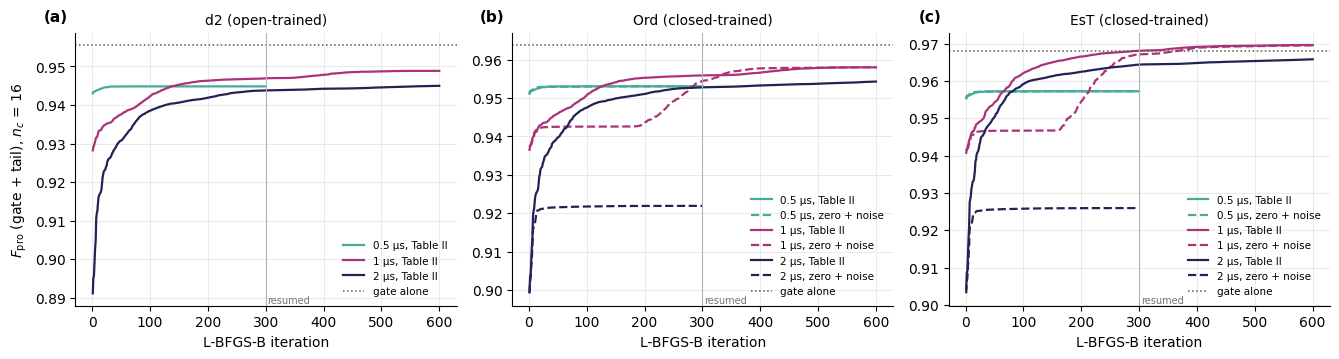

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(13.5, 3.7), sharey=False)
for ax, g in zip(axes, TAIL_GATES):
    for (gg, T, s), r in RUNS.items():
        if gg != g:
            continue
        h = r["info"]["history"]
        ax.plot([e["it"] for e in h], [e["F_pro"] for e in h], color=T_COL[T],
                ls="-" if s == "t2" else "--", lw=1.6, label=f"{T:g} μs, {STARTS[s]}")
    ax.axhline(F_ALONE[g], color="0.35", ls=":", lw=1.1, label="gate alone")
    if any(r["resumed"] for (gg, _, _), r in RUNS.items() if gg == g):
        ax.axvline(300, color="0.7", lw=0.8)
        ax.text(303, ax.get_ylim()[0], "resumed", fontsize=7, color="0.45", va="bottom")
    ax.set_title(GATE_LONG[g], fontsize=10)
    ax.set_xlabel("L-BFGS-B iteration")
    tidy(ax)
axes[0].set_ylabel(r"$F_{\rm pro}$ (gate + tail), $n_c$ = 16")
for ax, k in zip(axes, "abc"):
    ax.legend(fontsize=7.5, frameon=False, loc="lower right")
    panel(ax, k)
fig.tight_layout()
fig.savefig("figures/fwm_tails_training.png", dpi=150)
plt.show()

**Figure 4. Training curves:** (a) d2, (b) Ord, (c) EsT. Color = tail length (teal 0.5 μs, wine 1 μs, indigo 2 μs); solid = Table II start, dashed = zero +
noise; dotted = the gate alone, which a tail must end above. The grey vertical line at iteration 300 marks where the
resumed runs restart. Vertical scales differ between panels.
*Symbols:* $F_{\rm pro}$ of gate + tail at $n_c = 16$.

**What Table 10 and Figure 4 show.** The runs split into two kinds: those that built large pumps and those that
stalled at a nearly empty tail.

- **Climbed:** every 1 μs run and the 2 μs Table II runs. They grew large pumps ($|\eta_2|$ 0.093–0.100, $|\eta_1|$
  0.05–0.07). After 600 iterations the 1 μs runs have stopped (at most $7\times10^{-5}$ over the last 50 iterations);
  the 2 μs runs still rise by $(1.8$–$3.2)\times10^{-4}$.
- **Stalled:** all five 0.5 μs runs and both 2 μs zero starts, within about 30 iterations, at a nearly empty tail
  ($\max|\eta_1| \approx 0.012$, $|\eta_2| \le 0.005$). The 1 μs zero starts sat on the same kind of plateau for about
  160 iterations before leaving it, so it is a flat region, not a wall.
- **At 1 μs the two starts agree** (EsT 0.96966 and 0.96956; Ord 0.95799 and 0.95801) and give the same waveform
  (Figure 6): very likely the same optimum. No pre-image entry hit the box.

## 6.2 The main comparison

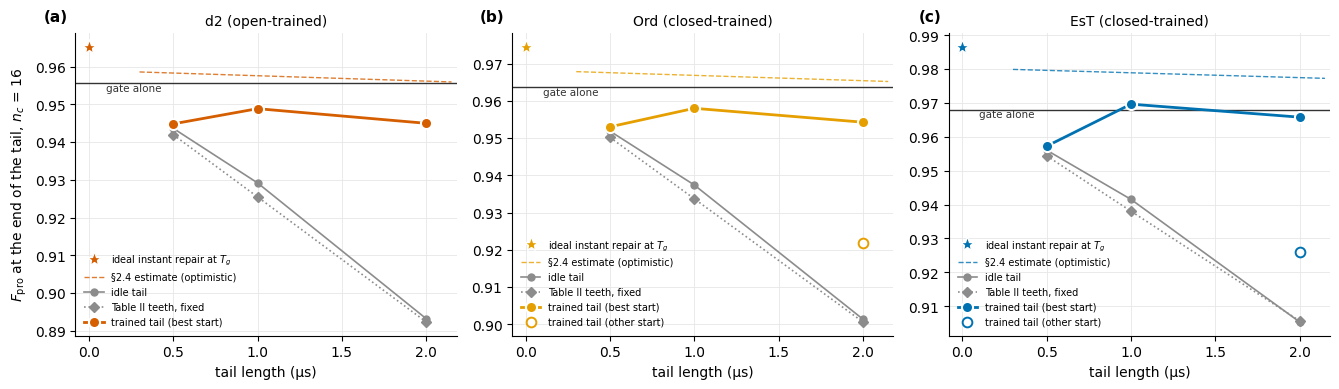

In [17]:
GAIN_REPAIR = {g: dict((k, v) for _, k, v, _ in dict(cmp_rows)[GATE_LONG[g]])["gain of the ideal repair"]
               for g in TAIL_GATES}
Tgrid = np.linspace(TAU_REPAIR, 2.15, 371)               # the estimate assumes no repair before tau
fig, axes = plt.subplots(1, 3, figsize=(13.5, 4.0))
for ax, g in zip(axes, TAIL_GATES):
    c = GCOL[g]
    ax.axhline(F_ALONE[g], color="0.2", lw=1.0)
    ax.text(0.1, F_ALONE[g], "gate alone", fontsize=7.5, ha="left", va="top", color="0.2")
    ax.plot(0, F_ALONE[g] + GAIN_REPAIR[g], marker="*", ms=11, color=c, mec="white", mew=1.0, ls="none",
            label="ideal instant repair at $T_g$")
    est = [F_ALONE[g] + tail_estimate(GAIN_REPAIR[g], T)[3] for T in Tgrid]
    ax.plot(Tgrid, est, color=c, ls="--", lw=1.0, alpha=0.8, label="§2.4 estimate (optimistic)")
    ax.plot(TAIL_T, [F_IDLE[(g, T)] for T in TAIL_T], color="0.55", marker="o", ms=5, lw=1.2, label="idle tail")
    ax.plot(TAIL_T, [F_TEETH[(g, T)] for T in TAIL_T], color="0.55", marker="D", ms=5, lw=1.2, ls=":",
            label="Table II teeth, fixed")
    best = [RUNS[(g, T, BEST[(g, T)])]["info"]["F_pro"] for T in TAIL_T]
    ax.plot(TAIL_T, best, color=c, lw=2.0, marker="o", ms=8, mec="white", mew=1.5, zorder=4,
            label="trained tail (best start)")
    for (gg, T, s), r in RUNS.items():
        if gg == g and s != BEST[(g, T)]:
            ax.plot(T, r["info"]["F_pro"], marker="o", ms=7, mfc="white", mec=c, mew=1.4, ls="none",
                    label="trained tail (other start)" if T == TAIL_T[0] else None)
    ax.set_title(GATE_LONG[g], fontsize=10)
    ax.set_xlabel("tail length (μs)")
    ax.set_xlim(-0.08, 2.18)
    tidy(ax)
axes[0].set_ylabel(r"$F_{\rm pro}$ at the end of the tail, $n_c$ = 16")
for ax, k in zip(axes, "abc"):
    ax.legend(fontsize=7, frameon=False, loc="lower left")
    panel(ax, k)
fig.tight_layout()
fig.savefig("figures/fwm_tails_main_comparison.png", dpi=150)
plt.show()

**Figure 5. Fidelity against tail length:** (a) d2, (b) Ord, (c) EsT. Black line: the gate alone. Star: the ideal
instant repair at $T_g$ (no tail time). Dashed: the gate alone plus the §2.4 estimate. Grey: the fixed tails (idle;
Table II teeth). Colour: the trained tails, filled for the better start and open for the other (hidden where both
starts agree).
*Symbols:* $F_{\rm pro}$ at the end of the tail, $n_c = 16$.

In [18]:
gain_rows = []
for (g, T, s), r in RUNS.items():
    tr = HELD[(HELD.tag == r["tag"])].set_index("condition")
    a, b = HELD_NC[g]
    gain_rows.append({"gate": g, "tail (us)": T, "start": STARTS[s], "best start": s == BEST[(g, T)],
                      "gain, n_c 16 (train)": tr.loc["train", "gain_vs_alone"],
                      "held-out n_c": f"{a}, {b}",
                      "gain, lower held-out n_c": tr.loc["nc_a", "gain_vs_alone"],
                      "gain, higher held-out n_c": tr.loc["nc_b", "gain_vs_alone"],
                      "F difference between held-out n_c": abs(tr.loc["nc_a", "F_pro"] - tr.loc["nc_b", "F_pro"]),
                      "§2.4 estimate": tail_estimate(GAIN_REPAIR[g], T)[3]})
GAIN_TAB = pd.DataFrame(gain_rows)
gcols = [c for c in GAIN_TAB.columns if c.startswith("gain") or c == "§2.4 estimate"]
display(GAIN_TAB.rename(columns=MU).style.hide(axis="index")
        .format({**{c: "{:+.2%}" for c in gcols}, "tail (μs)": "{:g}", "F difference between held-out n_c": "{:.1e}"})
        .set_caption("Table 11. Gain of each trained tail over its gate alone"))

gate,tail (μs),start,best start,"gain, n_c 16 (train)",held-out n_c,"gain, lower held-out n_c","gain, higher held-out n_c",F difference between held-out n_c,§2.4 estimate
d2,0.5,Table II,True,-1.07%,"18, 20",-1.07%,-1.07%,4.5e-07,+0.27%
d2,1,Table II,True,-0.67%,"18, 20",-0.67%,-0.67%,4.6e-07,+0.20%
d2,2,Table II,True,-1.06%,"18, 20",-1.06%,-1.06%,4.6e-07,+0.06%
Ord,0.5,Table II,True,-1.08%,"24, 28",-1.08%,-1.08%,3.6e-06,+0.38%
Ord,0.5,zero + noise,False,-1.08%,"24, 28",-1.08%,-1.08%,3.6e-06,+0.38%
Ord,1,Table II,False,-0.58%,"24, 28",-0.58%,-0.58%,3.6e-06,+0.31%
Ord,1,zero + noise,True,-0.58%,"24, 28",-0.58%,-0.58%,3.6e-06,+0.31%
Ord,2,Table II,True,-0.95%,"24, 28",-0.95%,-0.95%,3.6e-06,+0.16%
Ord,2,zero + noise,False,-4.19%,"24, 28",-4.19%,-4.19%,3.5e-06,+0.16%
EsT,0.5,Table II,True,-1.08%,"24, 28",-1.08%,-1.08%,1.4e-07,+1.16%


**Table 11. Gain of each trained tail over its gate alone**, at the training truncation and at the two held-out
truncations (gate and tail re-run without the cut), next to the §2.4 estimate.
*Symbols:* held-out $n_c$ = 18 and 20 for d2, 24 and 28 for EsT and Ord; F difference between held-out $n_c$ = the
change in $F_{\rm pro}$ between those two truncations.

**What Figure 5 and Table 11 show.** Only one tail beats its gate alone: EsT + 1 μs, with $F_{\rm pro}$ 0.96966 against
0.96803, **+0.16 %**. That is below the +0.3 % bar and about a seventh of the §2.4 estimate (+1.09 %; §6.5 explains
the gap).

- After Ord and d2 the best tails (also 1 μs) end 0.58 % and 0.67 % below their gates alone. Against an idle tail of
  the same length, though, every trained tail gains a lot (+2.0 to +2.8 % at 1 μs, +5 to +6 % at 2 μs): the tails undo
  most of what their own time costs, and only after EsT more than that.
- **1 μs is the best length for every gate.** 0.5 μs stalls at an almost idle tail (+0.12 % over idle); 2 μs ends
  below 1 μs, because the extra time costs more than it wins.
- **The ranking follows §3.** The EsT tail gains 0.74 % more over its gate than the Ord tail does over its gate; their
  ideal-repair gains differ by 0.78 %. Truncation is safe: the held-out $n_c$ change no gain by more than
  $4\times10^{-6}$.

## 6.3 The trained waveforms, and when the shot runs

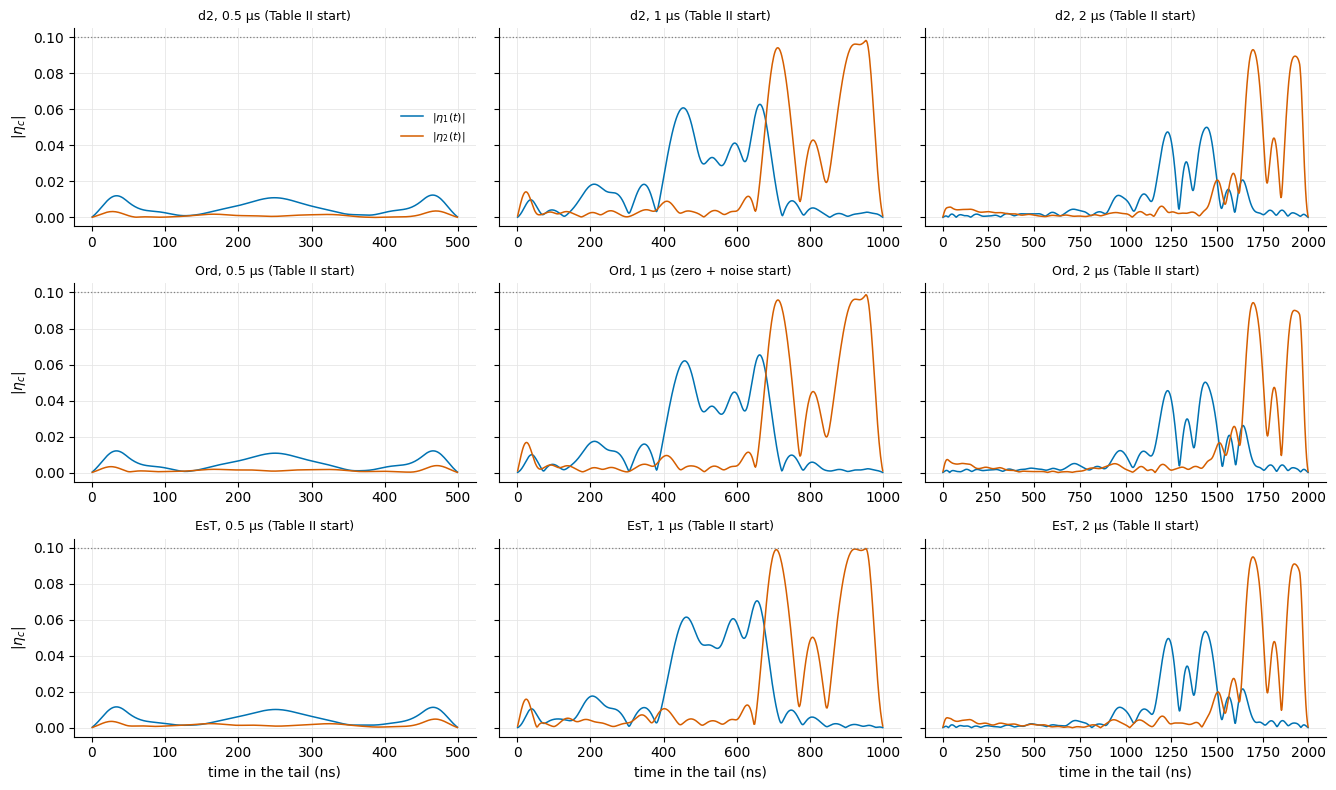

In [19]:
fig, axes = plt.subplots(3, 3, figsize=(13.5, 8.0), sharey=True)
for i, g in enumerate(TAIL_GATES):
    for j, T in enumerate(TAIL_T):
        ax = axes[i, j]
        eta = RUNS[(g, T, BEST[(g, T)])]["eta"]
        t_ns = (np.arange(len(eta)) + 0.5) * DT * 1e3
        for c, col in ((0, OKABE[0]), (1, OKABE[4])):
            ax.plot(t_ns, np.abs(eta[:, c]), color=col, lw=1.1, label=fr"$|\eta_{c + 1}(t)|$")
        ax.axhline(ft.ETA_CAP, color="0.5", ls=":", lw=0.9)
        ax.set_title(f"{g}, {T:g} μs ({STARTS[BEST[(g, T)]]} start)", fontsize=9)
        if i == 2:
            ax.set_xlabel("time in the tail (ns)")
        if j == 0:
            ax.set_ylabel(r"$|\eta_c|$")
        tidy(ax)
axes[0, 0].legend(fontsize=8, frameon=False)
fig.tight_layout()
fig.savefig("figures/fwm_tails_waveforms.png", dpi=150)
plt.show()

**Figure 6. The trained waveforms,** for the better start of each gate (rows) and length (columns). Blue:
$|\eta_1(t)|$ (comb 1); vermilion: $|\eta_2(t)|$ (comb 2); dotted: the cap 0.1.
*Symbols:* $\eta_c$ = the comb waveforms of §4.1; time is counted from the start of the tail.

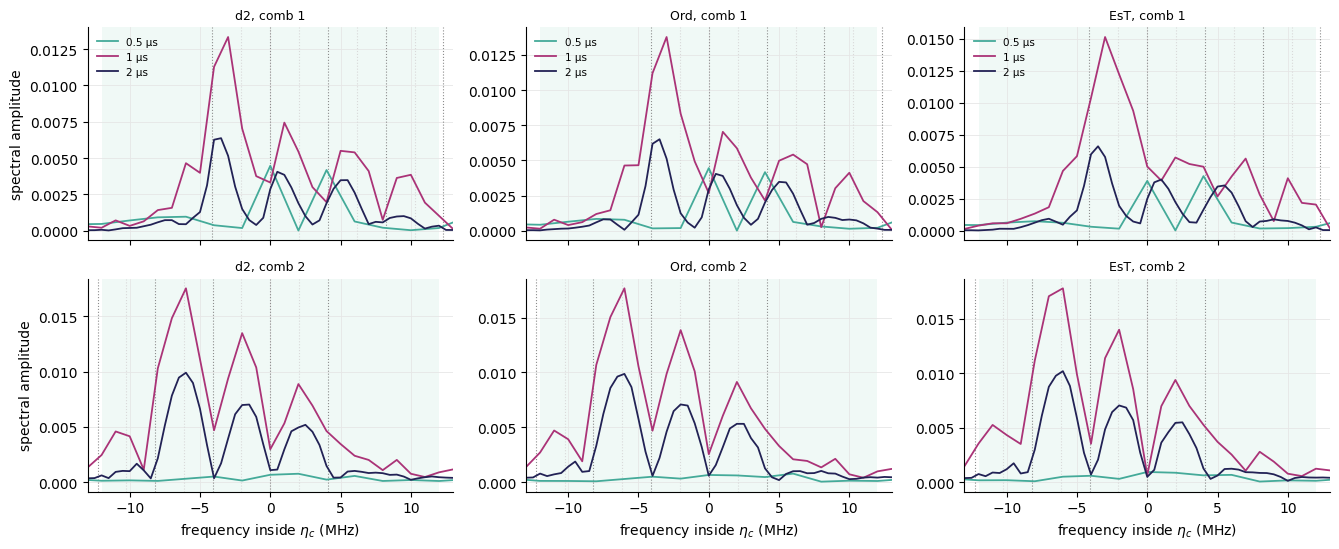

In [20]:
off5 = ft.tooth_offsets(N_C, ft.N_REF, fwm.FULL_PATHS)
fig, axes = plt.subplots(2, 3, figsize=(13.5, 5.6), sharex=True)
for j, g in enumerate(TAIL_GATES):
    for c in range(2):
        ax = axes[c, j]
        for n, x in zip(off5["paths"], mhz(off5[f"comb{c + 1}"])):
            ax.axvline(x, color="0.55" if n % 2 else "0.85", lw=0.8, ls=":")
        for T in TAIL_T:
            eta = RUNS[(g, T, BEST[(g, T)])]["eta"][:, c]
            freq = np.fft.fftshift(np.fft.fftfreq(len(eta), DT))
            ax.plot(freq, np.abs(np.fft.fftshift(np.fft.fft(eta))) / len(eta), color=T_COL[T], lw=1.3,
                    label=f"{T:g} μs")
        ax.axvspan(*ft.ETA_BAND, color=OKABE[2], alpha=0.06, lw=0)
        ax.set_xlim(-13, 13)
        ax.set_title(f"{g}, comb {c + 1}", fontsize=9)
        if c == 1:
            ax.set_xlabel(r"frequency inside $\eta_c$ (MHz)")
        if j == 0:
            ax.set_ylabel("spectral amplitude")
        tidy(ax)
    axes[0, j].legend(fontsize=7.5, frameon=False)
fig.tight_layout()
fig.savefig("figures/fwm_tails_spectra.png", dpi=150)
plt.show()

**Figure 7. Spectra of the trained waveforms.** Upper row comb 1, lower row comb 2; one color per tail length (teal 0.5 μs, wine 1 μs, indigo 2 μs).
Amplitude per frequency bin, so tails of different length compare directly. Dotted: the bare teeth of Table 7 (darker
for repair teeth, lighter for teeth that start from a code word). Green: the band.
*Symbols:* frequency = offset inside $\eta_c$, as in Table 7.

**What Figures 6 and 7 show.** Every working tail ends with one *repair shot*: comb 1, then comb 2.

- The shape is the same after every gate and from both starts: almost nothing at first, then one comb-1 burst (about
  300 ns, $|\eta_1|$ up to 0.05–0.07), then comb 2 near the cap. The whole shot takes about 600 ns. The 2 μs tails play
  the same sequence in their last 0.8 μs and stay nearly idle before it. A 0.5 μs tail with its 48 ns ramps has no
  room for the shot, which fits the 0.5 μs runs stalling.
- So the optimizer did not build a continuous comb, as PReSPA uses, but one timed shot.
- **The peaks are shifted from the repair teeth they serve.** Comb 1 peaks near −3 MHz (its tooth $n = 1$ sits at
  −4.1); comb 2 peaks near −6, −2 and +2 MHz, each about 2 MHz below its repair tooth (−4.1, 0, +4.1). The −6 MHz peak
  serves tooth 5, even though it lands near where tooth 6 would sit unshifted. Shifts of 1–2 MHz match the Stark shift
  at these amplitudes (2π·538 MHz·$|\xi|^2$: 2 MHz at 0.06, 5 MHz at 0.1). The tails aim at the shifted lines, which
  is why switching the Stark shift off ruins them (§6.6).

### Why the shot sits at the end of the tail

In Figure 6 the 1 μs and 2 μs tails stay almost idle at first and play their shot at the very end. The reason is when
photons are lost. The shot can repair only a photon lost *before* it runs. A photon lost after the shot is lost for
good and its whole branch fails, while one lost before the shot is repaired, up to the kitten limit. So idle time
before the shot is almost free, while idle time after it costs about $\bar n\kappa_a$ = 2.2 % per μs. With the tail
length fixed, the spare time belongs at the front.

The cell below tests this on the EsT tails ($n_c = 16$, gate cut from 24) in two ways:

- **Which losses get repaired.** One photon loss at time $t$ in the tail, with no other jump anywhere; that branch is
  scored at the end of the tail (its conditional $F_{\rm pro}$).
- **Sliding the shot.** The trained shot (the whole 1 μs tail, or the last 1.1 μs of the 2 μs tail, which includes the
  comb-1 lead-in) is placed in a 2 μs window with idle time before and after it, and scored with all decay channels,
  with photon loss only, and closed.

The results are cached in `tables/fwm_tail_shot_timing.csv` (delete it to recompute, about 4 min with 8 jobs).

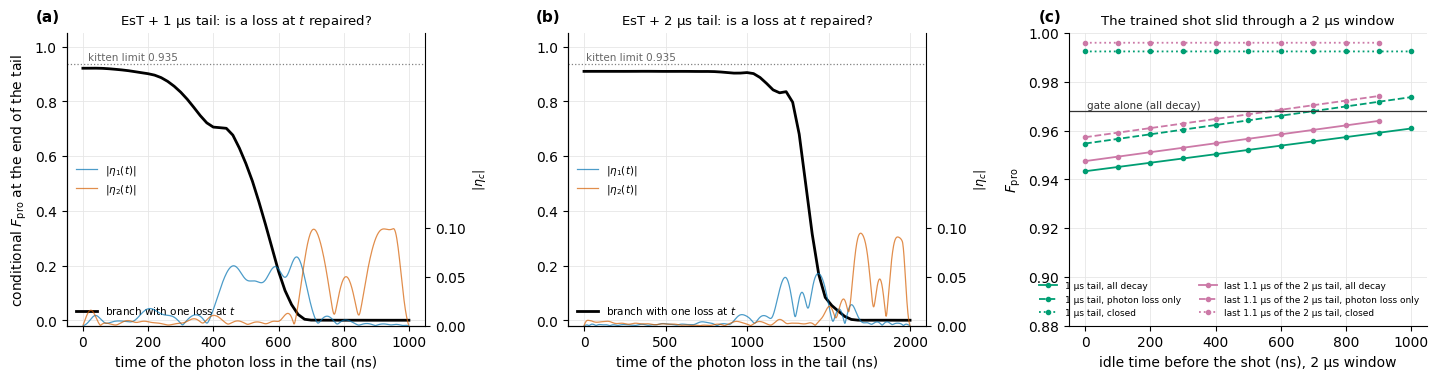

0.5 μs tail: repairs no loss (max branch F 1.2e-04)
1 μs tail: a loss before the shot is repaired to 0.921; below half of that from 540 ns; unrepaired window 492 ns, costing about 1.00%
2 μs tail: a loss before the shot is repaired to 0.910; below half of that from 1400 ns; unrepaired window 618 ns, costing about 1.24%
1 μs tail: F_pro 0.94333 (earliest) -> 0.96085 (latest); gain per μs later: all decay +1.75%, photon loss only +1.90%, closed -0.00%
last 1.1 μs of the 2 μs tail: F_pro 0.94748 (earliest) -> 0.96396 (latest); gain per μs later: all decay +1.83%, photon loss only +1.88%, closed -0.00%
for reference: EsT alone 0.96803; trained 2 μs tail 0.96582; expected slope if every loss before the shot were repaired to the kitten limit: 2.06% per μs


In [21]:
# Why the shot sits at the end of the tail (EsT gate). Two tests, cached in tables/fwm_tail_shot_timing.csv:
#  loss time: one photon lost at time t in the tail, gate and tail otherwise closed; the conditional F_pro of
#             that branch at the end of the tail says whether the tail repairs a loss at t;
#  slide:     the trained shot placed in a 2 us window with idle before and after, scored with all decay,
#             photon loss only, and closed. Delete the CSV to recompute (about 4 min with 8 jobs).
SHOT_CSV = "tables/fwm_tail_shot_timing.csv"
G_SHOT = "EsT"
U_SHOT = np.load(TAIL_GATES[G_SHOT])
W_SLIDE = ft.n_steps(2.0)
SLIDE_COND = {"all decay": {}, "photon loss only": {"keep": {"a"}}, "closed": {"keep": set()}}


def best_eta(T):
    return RUNS[(G_SHOT, T, BEST[(G_SHOT, T)])]["eta"]


def loss_branch_profile(eta, stride):
    tm = ft.tail_model(N_C, 2, keep=set())
    Tt, Wt = ft.tail_targets(N_C, 2)
    R = ft.tail_input(U_SHOT, N_C, 2, TAIL_GATE_NC[G_SHOT], keep=set())
    a = operators(N_C, 2)["a"]
    rows = []
    for k in range(0, len(eta) + 1, stride):
        Rb = np.einsum("ij,bjk,lk->bil", a, R, a.conj())                # one photon lost at t_k
        p = np.mean([np.real(np.trace(Rb[b])) for b in (0, 1)])         # branch weight / (kappa_a dt)
        Rend = ft.propagate(tm, eta[k:], Rb)[0] if k < len(eta) else Rb
        rows.append({"t_ns": k * DT * 1e3, "f_branch": ft.fidelity_from_outputs(Rend, Tt, Wt) / p})
        if k < len(eta):
            R = ft.propagate(tm, eta[k:k + stride], R)[0]
    return rows


def slide_score(label, shot, d, cond):
    eta = np.zeros((W_SLIDE, 2), complex)
    eta[d:d + len(shot)] = shot
    F_ = ft.score(eta, n_c=N_C, pulse=U_SHOT, gate_n_c=TAIL_GATE_NC[G_SHOT], **SLIDE_COND[cond])["F_pro"]
    return {"test": "slide", "shot": label, "delay_ns": d * DT * 1e3, "condition": cond, "F_pro": F_}


SHOTS = {"1 μs tail": best_eta(1.0), "last 1.1 μs of the 2 μs tail": best_eta(2.0)[-ft.n_steps(1.1):]}
if not os.path.exists(SHOT_CSV):
    from joblib import Parallel, delayed
    prof = Parallel(n_jobs=3)(delayed(loss_branch_profile)(best_eta(T), s) for T, s in ((0.5, 10), (1.0, 10), (2.0, 20)))
    rows = [{"test": "loss time", "tail_us": T, **r} for T, p in zip((0.5, 1.0, 2.0), prof) for r in p]
    jobs = [(lab, sh, d, c) for lab, sh in SHOTS.items() for d in range(0, W_SLIDE - len(sh) + 1, 50)
            for c in SLIDE_COND]
    rows += Parallel(n_jobs=8)(delayed(slide_score)(*j) for j in jobs)
    pd.DataFrame(rows).to_csv(SHOT_CSV, index=False)
SHOT = pd.read_csv(SHOT_CSV)
LP, SL = SHOT[SHOT.test == "loss time"], SHOT[SHOT.test == "slide"]

fig, axes = plt.subplots(1, 3, figsize=(14.5, 3.9))
for ax, T in zip(axes, (1.0, 2.0)):
    g = LP[np.isclose(LP.tail_us, T)]
    eta = best_eta(T)
    t_ns = (np.arange(len(eta)) + 0.5) * DT * 1e3
    ax2 = ax.twinx()
    for c, col in ((0, OKABE[0]), (1, OKABE[4])):
        ax2.plot(t_ns, np.abs(eta[:, c]), color=col, lw=0.9, alpha=0.7, label=fr"$|\eta_{c + 1}(t)|$")
    ax2.set_ylim(0, 0.3)
    ax2.set_yticks([0, 0.05, 0.1])
    ax2.set_ylabel(r"$|\eta_c|$", fontsize=9)
    ax2.spines["top"].set_visible(False)
    ax.plot(g.t_ns, g.f_branch, color="k", lw=2.0, label="branch with one loss at $t$")
    ax.axhline(F_KITTEN, color="0.5", ls=":", lw=0.9)
    ax.text(15, F_KITTEN + 0.015, f"kitten limit {F_KITTEN:.3f}", fontsize=7.5, color="0.4")
    ax.set_ylim(-0.02, 1.05)
    ax.set_xlabel("time of the photon loss in the tail (ns)")
    ax.set_title(f"{G_SHOT} + {T:g} μs tail: is a loss at $t$ repaired?", fontsize=9.5)
    ax.legend(fontsize=7.5, frameon=False, loc="lower left")
    ax2.legend(fontsize=7.5, frameon=False, loc="center left")
    tidy(ax)
axes[0].set_ylabel(r"conditional $F_{\rm pro}$ at the end of the tail")
for ax, k in zip(axes, "abc"):
    panel(ax, k)
ax = axes[2]
for (lab, sh), col in zip(SHOTS.items(), (OKABE[2], OKABE[3])):
    for cond, ls in zip(SLIDE_COND, ("-", "--", ":")):
        g = SL[(SL.shot == lab) & (SL.condition == cond)]
        ax.plot(g.delay_ns, g.F_pro, color=col, ls=ls, marker="o", ms=3, lw=1.3, label=f"{lab}, {cond}")
ax.axhline(F_ALONE[G_SHOT], color="0.2", lw=0.9)
ax.text(5, F_ALONE[G_SHOT] + 0.001, "gate alone (all decay)", fontsize=7.5, color="0.2")
ax.set_ylim(0.88, 1.0)
ax.set_xlabel("idle time before the shot (ns), 2 μs window")
ax.set_ylabel(r"$F_{\rm pro}$")
ax.set_title("The trained shot slid through a 2 μs window", fontsize=9.5)
ax.legend(fontsize=6.5, frameon=False, ncol=2, loc="lower right")
tidy(ax)
fig.tight_layout()
fig.savefig("figures/fwm_tails_shot_timing.png", dpi=150)
plt.show()

UNPROT = {}                                                  # tail length -> weighted unrepaired window (us)
for T, g in LP.groupby("tail_us"):
    f0, f = g.f_branch.iloc[0], g.f_branch.values
    if f0 < 0.5:
        print(f"{T:g} μs tail: repairs no loss (max branch F {f.max():.1e})")
        continue
    step_us = np.diff(g.t_ns).mean() / 1e3
    unprot = np.sum(1 - f[:-1] / f0) * step_us            # time whose losses go unrepaired, weighted
    UNPROT[T] = unprot
    t_half = g.t_ns.values[np.argmax(f < f0 / 2)]
    print(f"{T:g} μs tail: a loss before the shot is repaired to {f0:.3f}; below half of that from {t_half:.0f} ns; "
          f"unrepaired window {unprot * 1e3:.0f} ns, costing about {LOSS_RATE * f0 * unprot:.2%}")
for lab in SHOTS:
    g = SL[SL.shot == lab]
    slopes = {c: np.polyfit(gc.delay_ns / 1e3, gc.F_pro, 1)[0] for c, gc in g.groupby("condition")}
    ga = g[g.condition == "all decay"]
    print(f"{lab}: F_pro {ga.F_pro.iloc[0]:.5f} (earliest) -> {ga.F_pro.iloc[-1]:.5f} (latest); gain per μs later: "
          + ", ".join(f"{c} {slopes[c]:+.2%}" for c in SLIDE_COND))
print(f"for reference: {G_SHOT} alone {F_ALONE[G_SHOT]:.5f}; trained 2 μs tail {RUNS[(G_SHOT, 2.0, BEST[(G_SHOT, 2.0)])]['info']['F_pro']:.5f}; "
      f"expected slope if every loss before the shot were repaired to the kitten limit: {LOSS_RATE * F_KITTEN:.2%} per μs")

**Figure 8. Losses before the shot are repaired; losses after it are not.** (a, b) Conditional $F_{\rm pro}$ of a
branch with one photon loss at time $t$ (black), with the trained waveform behind it (right axis), for the EsT gate
with (a) the 1 μs tail and (b) the 2 μs tail. Dotted: the kitten limit. (c) $F_{\rm pro}$ of the EsT gate followed by
a 2 μs window as the trained shot moves later. Solid: all decay; dashed: photon loss only; dotted: closed. Black line:
the EsT gate alone.
*Symbols:* $n_c = 16$, gate cut from 24.

**What it shows.** The shot repairs only the losses before it, so the best place for spare time is in front of it.

- A loss in the quiet first part is repaired to 0.92 (1 μs tail) or 0.91 (2 μs), close to the kitten limit. The score
  falls while comb 1 runs and is zero once comb 1 is over. The 0.5 μs tail repairs no loss at all.
- In (c), $F_{\rm pro}$ rises in a straight line as the shot moves later: +1.75 % per μs (1 μs shot) and +1.83 % per μs
  (2 μs shot) with all decay, about +1.9 % with photon loss only, and nothing when closed. A simple count agrees:
  losses arrive at 2.2 % per μs, and moving one from after the shot (scored ≈ 0) to before it (≈ 0.92) gains
  ≈ 2.0 % per μs. Moving the shot 1 μs earlier would cost about 1.8 %, ten times the EsT tail's net gain.
- What is left is the shot itself. Weighted by how badly each loss is repaired, it leaves an unprotected window of
  about 490 ns in the 1 μs tail (620 ns in the 2 μs tail), worth about **1.0 %** (1.2 %). Spare time in front is cheap
  by comparison: going from a 1 μs to a 2 μs tail costs 0.38 %.

The latest slid shot in (c) scores 0.96085, below the trained 1 μs tail (0.96966). Most of the difference is the extra
1 μs of idle time in the 2 μs window, in which nothing cancels the Kerr phase: closed, the slid shot scores 0.9924
against 0.9978 for the trained tail, about what an idle 1 μs costs (0.6 %, Table 3).

## 6.4 What the tail does: repair, or something else?

A tail can raise the score in three ways: put lost photons back (a **repair**), cancel the storage Kerr phase of its
own time, or undo a little of the gate's coherent error. `fwm_grape`'s Stage 2 told these apart by switching channels
off, and Table 12 does the same, in the gate and the tail alike:

- **closed** (no jumps at all): a gain here cannot be a repair.
- **photon loss only** and **all but photon loss**: where the gain lives.
- **photon-loss cost** $= F(\text{all but photon loss}) - F(\text{all decay})$, for the gate alone, the gate + idle
  tail and the gate + trained tail. A repair makes the trained tail's loss cost smaller than the idle tail's, and
  ideally smaller than the gate alone's.

In [22]:
mech_rows = []
for (g, T), s in BEST.items():
    tag = RUNS[(g, T, s)]["tag"]
    tr = lambda cond: held("trained", g, cond, tag=tag)                       # noqa: E731
    al = lambda cond: held("alone", g, cond)                                  # noqa: E731
    idl = lambda cond: held("idle", g, cond, T=T)                             # noqa: E731
    mech_rows.append({"gate": g, "tail (us)": T,
                      "gain, all decay": tr("train").gain_vs_alone,
                      "gain, closed": tr("closed").gain_vs_alone,
                      "gain, photon loss only": tr("loss_only").gain_vs_alone,
                      "gain, all but photon loss": tr("no_loss").gain_vs_alone,
                      "gain, Stark off": tr("stark_off").gain_vs_alone,
                      "loss cost: gate alone": al("no_loss").F_pro - al("train").F_pro,
                      "loss cost: + idle": idl("no_loss").F_pro - idl("train").F_pro,
                      "loss cost: + trained": tr("no_loss").F_pro - tr("train").F_pro})
MECH = pd.DataFrame(mech_rows).sort_values(["gate", "tail (us)"])
display(MECH.rename(columns=MU).style.hide(axis="index")
        .format({**{c: "{:+.2%}" for c in MECH.columns[2:]}, "tail (μs)": "{:g}"})
        .set_caption("Table 12. Where the gain comes from: channel split"))

gate,tail (μs),"gain, all decay","gain, closed","gain, photon loss only","gain, all but photon loss","gain, Stark off",loss cost: gate alone,loss cost: + idle,loss cost: + trained
EsT,0.5,-1.08%,+0.00%,-1.07%,-0.02%,-1.08%,+2.22%,+3.27%,+3.28%
EsT,1,+0.16%,-0.01%,+0.57%,-0.24%,-63.14%,+2.22%,+4.30%,+1.81%
EsT,2,-0.22%,-0.00%,+0.04%,-0.21%,-18.19%,+2.22%,+6.22%,+2.22%
Ord,0.5,-1.08%,-0.00%,-1.07%,-0.02%,-1.08%,+2.39%,+3.44%,+3.44%
Ord,1,-0.58%,-0.01%,-0.24%,-0.22%,-41.77%,+2.39%,+4.46%,+2.75%
Ord,2,-0.95%,-0.01%,-0.71%,-0.20%,-13.35%,+2.39%,+6.37%,+3.14%
d2,0.5,-1.07%,-0.00%,-1.07%,-0.02%,-1.08%,+2.37%,+3.41%,+3.42%
d2,1,-0.67%,-0.01%,-0.35%,-0.21%,-33.84%,+2.37%,+4.43%,+2.83%
d2,2,-1.06%,-0.00%,-0.83%,-0.19%,-14.19%,+2.37%,+6.33%,+3.24%


**Table 12. Where the gain comes from,** for the better start of each gate and length. Gains are against the gate
alone with the same channels on.
*Symbols:* closed = no jumps; all but photon loss = the decay set without storage photon loss; Stark off = the same
waveform scored without the Stark term; loss cost = $F$(all but photon loss) − $F$(all decay), for the gate alone,
gate + idle tail of the same length, and gate + trained tail.

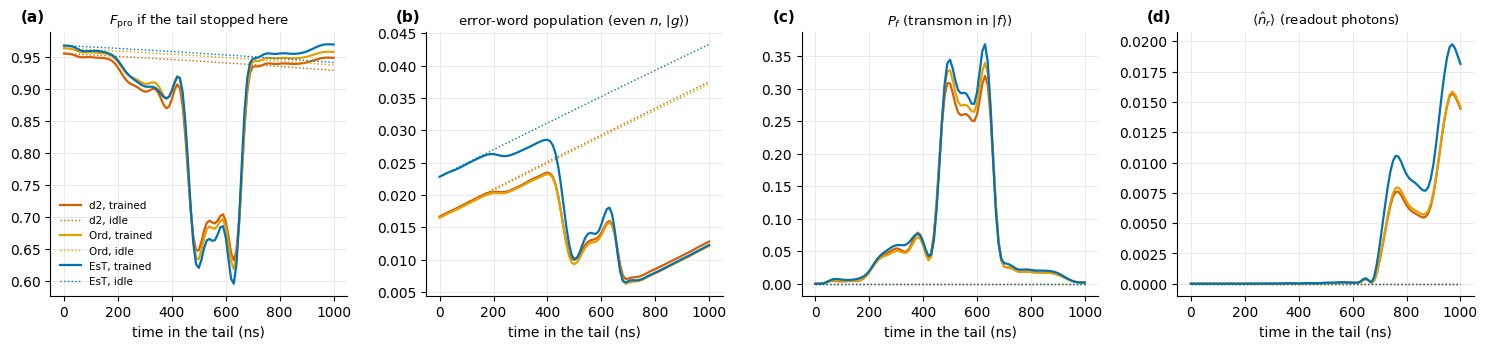

In [23]:
def tail_trace(g, eta, chunk=5):
    # Observables over the tail, every chunk * 2 ns, averaged over the code inputs |0_L>, |1_L>; F_pro if the
    # tail stopped there. Chunking is exact: the frame has no carriers, so nothing depends on absolute time.
    pulse = None if TAIL_GATES[g] is None else np.load(TAIL_GATES[g])
    R = ft.tail_input(pulse, N_C, 2, TAIL_GATE_NC[g])
    tm = ft.tail_model(N_C, 2)
    Tt, Wt = ft.tail_targets(N_C, 2)
    o = operators(N_C, 2)
    d = tm.model.d
    n_of, j_of = np.arange(d) // 6, (np.arange(d) // 2) % 3
    err_g = ((n_of % 2 == 0) & (j_of == G)).astype(float)                    # even photon number, transmon g
    pe, pf, nr = (np.real(np.diag(o[k])) for k in ("Pe", "Pf", "n_r"))

    def obs(R, k):
        dg = np.real(np.einsum("bii->bi", R[:2])).mean(0)
        return {"t_ns": k * DT * 1e3, "F": ft.fidelity_from_outputs(R, Tt, Wt), "P_err": dg @ err_g,
                "P_e": dg @ pe, "P_f": dg @ pf, "n_r": dg @ nr}
    rows = [obs(R, 0)]
    for k in range(0, len(eta), chunk):
        R, _ = ft.propagate(tm, eta[k:k + chunk], R)
        rows.append(obs(R, min(k + chunk, len(eta))))
    return pd.DataFrame(rows)


T_SHOW = 1.0
traces = {}
for g in TAIL_GATES:
    eta = RUNS[(g, T_SHOW, BEST[(g, T_SHOW)])]["eta"]
    traces[(g, "trained")] = tail_trace(g, eta)
    traces[(g, "idle")] = tail_trace(g, np.zeros_like(eta))
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for (g, kind), tr in traces.items():
    for ax, key in zip(axes, ("F", "P_err", "P_f", "n_r")):
        ax.plot(tr.t_ns, tr[key], color=GCOL[g], lw=1.6 if kind == "trained" else 1.0,
                ls="-" if kind == "trained" else ":", label=f"{g}, {kind}")
for ax, lab in zip(axes, (r"$F_{\rm pro}$ if the tail stopped here",
                          "error-word population (even $n$, $|g\\rangle$)",
                          r"$P_f$ (transmon in $|f\rangle$)", r"$\langle\hat n_r\rangle$ (readout photons)")):
    ax.set_title(lab, fontsize=9.5)
    ax.set_xlabel("time in the tail (ns)")
    tidy(ax)
axes[0].legend(fontsize=7.5, frameon=False)
for ax, k in zip(axes, "abcd"):
    panel(ax, k)
fig.tight_layout()
fig.savefig("figures/fwm_tails_traces.png", dpi=150)
plt.show()

**Figure 9. Inside the 1 μs tail:** the better trained tail of each gate (solid) against an idle tail (dotted),
averaged over the two code inputs. (a) $F_{\rm pro}$ if the tail stopped at that moment; (b) population in error words
(even photon number, transmon in $|g\rangle$); (c) $P_f$; (d) readout photons.
*Symbols:* $P_f$ = transmon population in $|f\rangle$; $\langle\hat n_r\rangle$ = mean readout photon number.

**What Table 12 and Figure 9 show.** The gain is a real repair of photon loss, paid for mostly by transmon decay.

- **No coherent gain.** Closed, every tail scores within $1.2\times10^{-4}$ of its gate alone: it cancels the Kerr
  phase of its own time (0.6 % for an idle 1 μs) and adds nothing on top.
- **A repair.** With photon loss as the only channel, the EsT 1 μs tail gains +0.57 %. Its photon-loss cost is 1.81 %:
  below the idle tail's 4.30 % and below the gate alone's 2.22 %. After Ord and d2 the trained tails cut the loss cost
  well below the idle tail's (2.75 % against 4.46 %; 2.83 % against 4.43 %) but not below the gate alone's (2.39 %,
  2.37 %). Figure 9 shows the steps: from about 400 ns comb 1 moves error words into $|f\rangle$, comb 2 returns them to
  $|g\rangle$ and sends a photon into the readout, and the error-word population falls to 0.007 for every gate. EsT
  starts with more error words (0.023 against 0.017): §3's "keeps losses repairable", seen directly.
- **The price, most likely transmon decay.** With every channel except photon loss on, each 1 μs and 2 μs tail loses
  about 0.2 % against the gate alone, and up to 37 % of the population sits in $|f\rangle$ during the shot. Mid-shot
  $F_{\rm pro}$ dips to about 0.6 because comb 1 also moves code-word population, so the shot must finish with exactly
  the right pulse areas. That is why it is sensitive to the pump amplitude (§6.6).

## 6.5 Why the gain is a seventh of the estimate

The §2.4 estimate for the EsT gate with a 1 μs tail was +1.09 %; the trained tail gains +0.16 %. The table below
accounts for most of the difference with quantities measured above. It is a rough budget: the effects overlap, so the
rows are not exactly additive, and the remainder row holds whatever is left.

In [24]:
# Section 2.4's estimate against the trained EsT 1 us tail: a rough budget built from numbers measured above
g, T = "EsT", 1.0
est_total = tail_estimate(GAIN_REPAIR[g], T)[3]
mrow = MECH[(MECH.gate == g) & np.isclose(MECH["tail (us)"], T)].iloc[0]
slow = -LOSS_RATE * F_KITTEN * (UNPROT[T] - TAU_REPAIR)      # losses in the extra window: lost instead of repaired
other = mrow["gain, all but photon loss"]
measured = mrow["gain, all decay"]
budget = pd.DataFrame({"step": [
    "§2.4 estimate (τ = 0.3 μs, perfect repair, no transmon decay)",
    f"the shot leaves {UNPROT[T] * 1e3:.0f} ns unprotected, not {TAU_REPAIR * 1e3:.0f} ns",
    "transmon decay and the other non-loss channels",
    "remainder: the gate's losses repaired less well than ideally, overlaps",
    "measured gain (Table 11)"],
    "change in F_pro": [est_total, slow, other, measured - est_total - slow - other, measured]})
display(budget.style.hide(axis="index").format({"change in F_pro": "{:+.2%}"})
        .set_caption("Table 13. From the §2.4 estimate to the measured gain, EsT gate, 1 μs tail"))

step,change in F_pro
"§2.4 estimate (τ = 0.3 μs, perfect repair, no transmon decay)",+1.09%
"the shot leaves 492 ns unprotected, not 300 ns",-0.40%
transmon decay and the other non-loss channels,-0.24%
"remainder: the gate's losses repaired less well than ideally, overlaps",-0.29%
measured gain (Table 11),+0.16%


**Table 13. From the §2.4 estimate to the measured gain** (EsT gate, 1 μs tail). The last row is the sum of the rows
above it.
*Symbols:* $\tau$ = the repair time the estimate assumed (0.3 μs); unprotected = the weighted time during the shot
whose losses go unrepaired (Figure 8a), costed at $\bar n\kappa_a \times 0.935$ per μs beyond $\tau$ (a loss moved
from "repaired to the kitten limit" to "lost"); the non-loss row is "gain, all but photon loss" from Table 12.

**What it shows.** The slow shot and the transmon decay during it explain about two thirds of the gap.

- The shot leaves about 490 ns unprotected instead of the assumed 300 ns: about −0.4 %.
- Transmon decay (and the other non-loss channels) during the shot, which the estimate ignored: about −0.2 %.
- The remaining ≈ −0.3 % is the gate's own losses, repaired less well than by the ideal instant repair, plus overlaps
  between the rows. A faster shot attacks the largest single term.

## 6.6 Held-out conditions

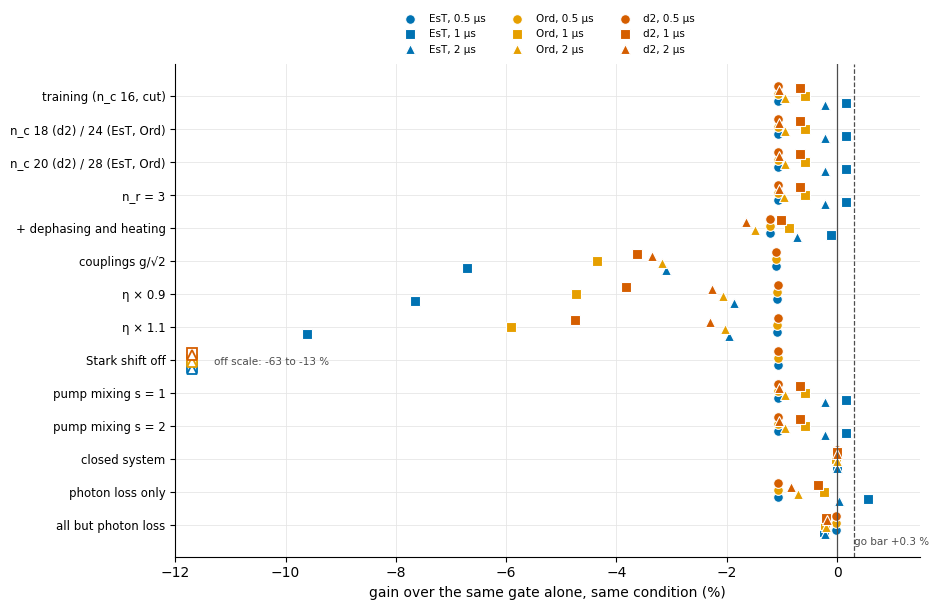

In [25]:
COND_LABEL = {"train": "training (n_c 16, cut)", "nc_a": "n_c 18 (d2) / 24 (EsT, Ord)", "nc_b": "n_c 20 (d2) / 28 (EsT, Ord)",
              "nr3": "n_r = 3", "all_ch": "+ dephasing and heating", "g/sqrt2": "couplings g/√2",
              "eta_x0.9": "η × 0.9", "eta_x1.1": "η × 1.1", "stark_off": "Stark shift off",
              "mix1": "pump mixing s = 1", "mix2": "pump mixing s = 2", "closed": "closed system",
              "loss_only": "photon loss only", "no_loss": "all but photon loss"}
conds = list(COND_LABEL)
fig, ax = plt.subplots(figsize=(9.5, 6.2))
ygap = {g: k for k, g in enumerate(TAIL_GATES)}
X_MIN = -12.0                                       # points further left are drawn open at the edge
off_scale = []
for (g, T), s in BEST.items():
    tr = HELD[HELD.tag == RUNS[(g, T, s)]["tag"]].set_index("condition")
    y = np.arange(len(conds)) + 0.22 * (ygap[g] - 1) + 0.06 * (TAIL_T.index(T) - 1)
    x = tr.loc[conds, "gain_vs_alone"].values * 100
    far = x < X_MIN
    off_scale += list(x[far])
    ax.plot(x[~far], y[~far], ls="none", marker=T_MARK[T], ms=7, color=GCOL[g], mec="white", mew=0.8,
            label=f"{g}, {T:g} μs")
    ax.plot(np.full(far.sum(), X_MIN + 0.3), y[far], ls="none", marker=T_MARK[T], ms=7, mfc="white",
            mec=GCOL[g], mew=1.3)
if off_scale:
    ax.text(X_MIN + 0.7, conds.index("stark_off") + 0.05, f"off scale: {min(off_scale):.0f} to {max(off_scale):.0f} %",
            fontsize=7.5, color="0.3", va="center")
ax.set_xlim(X_MIN, 1.5)
ax.axvline(0, color="0.3", lw=0.9)
ax.axvline(0.3, color="0.3", lw=0.9, ls="--")
ax.text(0.31, len(conds) - 0.4, "go bar +0.3 %", fontsize=7.5, color="0.3")
ax.set_yticks(np.arange(len(conds)))
ax.set_yticklabels([COND_LABEL[c] for c in conds], fontsize=8.5)
ax.invert_yaxis()
ax.set_xlabel("gain over the same gate alone, same condition (%)")
ax.legend(fontsize=7.5, frameon=False, ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.0))
tidy(ax)
fig.tight_layout()
fig.savefig("figures/fwm_tails_heldout.png", dpi=150)
plt.show()

**Figure 10. Gain over the gate alone under each held-out condition,** for the better start of each gate (colour) and
tail length (marker). Each condition changes the model used for scoring, and the gate alone is scored the same way.
Dashed: the +0.3 % go bar. Open markers at the left edge are off the scale (Stark off; values in Table 14).
*Symbols:* $n_r$ = readout levels kept; $g/\sqrt2$ = both pump couplings divided by $\sqrt2$; $s$ = strength of the
pump-mixing term; $\eta \times 0.9$, $\times 1.1$ = both pump amplitudes scaled.

In [26]:
run_label = {r["tag"]: f"{g} {T:g} μs, {'T-II' if s == 't2' else 'zero'}" for (g, T, s), r in RUNS.items()}   # the resumed run where there is one
piv = (HELD[HELD.tag.isin(run_label)].assign(run=lambda d: d.tag.map(run_label))
       .pivot(index="condition", columns="run", values="gain_vs_alone").loc[conds])
display(piv.rename(index=COND_LABEL).style.format("{:+.2%}")
        .set_caption("Table 14. Gain over the gate alone under each held-out condition, all runs"))

run,"EsT 0.5 μs, T-II","EsT 0.5 μs, zero","EsT 1 μs, T-II","EsT 1 μs, zero","EsT 2 μs, T-II","EsT 2 μs, zero","Ord 0.5 μs, T-II","Ord 0.5 μs, zero","Ord 1 μs, T-II","Ord 1 μs, zero","Ord 2 μs, T-II","Ord 2 μs, zero","d2 0.5 μs, T-II","d2 1 μs, T-II","d2 2 μs, T-II"
condition,,,,,,,,,,,,,,,
"training (n_c 16, cut)",-1.08%,-1.08%,+0.16%,+0.15%,-0.22%,-4.21%,-1.08%,-1.08%,-0.58%,-0.58%,-0.95%,-4.19%,-1.07%,-0.67%,-1.06%
"n_c 18 (d2) / 24 (EsT, Ord)",-1.08%,-1.08%,+0.16%,+0.15%,-0.22%,-4.21%,-1.08%,-1.08%,-0.58%,-0.58%,-0.95%,-4.19%,-1.07%,-0.67%,-1.06%
"n_c 20 (d2) / 28 (EsT, Ord)",-1.08%,-1.08%,+0.16%,+0.15%,-0.22%,-4.21%,-1.08%,-1.08%,-0.58%,-0.58%,-0.95%,-4.19%,-1.07%,-0.67%,-1.06%
n_r = 3,-1.08%,-1.08%,+0.16%,+0.15%,-0.23%,-4.21%,-1.08%,-1.08%,-0.58%,-0.58%,-0.96%,-4.19%,-1.07%,-0.67%,-1.06%
+ dephasing and heating,-1.21%,-1.21%,-0.11%,-0.12%,-0.73%,-4.70%,-1.21%,-1.21%,-0.88%,-0.88%,-1.49%,-4.67%,-1.21%,-1.02%,-1.65%
couplings g/√2,-1.11%,-1.11%,-6.71%,-4.98%,-3.10%,-4.72%,-1.11%,-1.11%,-3.60%,-4.35%,-3.17%,-4.70%,-1.10%,-3.64%,-3.36%
η × 0.9,-1.08%,-1.08%,-7.65%,-5.54%,-1.88%,-4.28%,-1.08%,-1.08%,-3.83%,-4.74%,-2.07%,-4.26%,-1.08%,-3.82%,-2.26%
η × 1.1,-1.08%,-1.08%,-9.62%,-7.10%,-1.96%,-4.29%,-1.08%,-1.08%,-4.79%,-5.91%,-2.03%,-4.27%,-1.08%,-4.74%,-2.31%
Stark shift off,-1.08%,-1.08%,-63.14%,-51.28%,-18.19%,-4.21%,-1.08%,-1.08%,-34.58%,-41.77%,-13.35%,-4.19%,-1.08%,-33.84%,-14.19%


**Table 14. Gain over the gate alone under each held-out condition, all fifteen runs.** Columns: gate, tail length
and start (T-II = Table II teeth, zero = zero + noise).
*Symbols:* each entry is $F_{\rm pro}$(gate + tail) − $F_{\rm pro}$(gate alone), both scored under that row's condition; the conditions are those of Figure 10.

In [27]:
end_rows = [{"gate": g, "tail (μs)": T, "⟨n_r⟩ at end": held("trained", g, tag=RUNS[(g, T, s)]["tag"]).n_r_end,
             "P_e at end": held("trained", g, tag=RUNS[(g, T, s)]["tag"]).P_e_end,
             "P_f at end": held("trained", g, tag=RUNS[(g, T, s)]["tag"]).P_f_end,
             "F_empty − F_pro": held("trained", g, tag=RUNS[(g, T, s)]["tag"]).F_empty
             - held("trained", g, tag=RUNS[(g, T, s)]["tag"]).F_pro}
            for (g, T), s in BEST.items()]
display(pd.DataFrame(end_rows).style.hide(axis="index")
        .format({"tail (μs)": "{:g}", "⟨n_r⟩ at end": "{:.1e}", "P_e at end": "{:.1e}", "P_f at end": "{:.1e}",
                 "F_empty − F_pro": "{:+.2%}"})
        .set_caption("Table 15. What is left at the end of the better tails"))

gate,tail (μs),⟨n_r⟩ at end,P_e at end,P_f at end,F_empty − F_pro
EsT,0.5,2.8e-06,6.7e-03,4.3e-03,-0.00%
EsT,1,1.8e-02,9.2e-03,1.8e-03,-1.59%
EsT,2,2.4e-02,9.0e-03,1.5e-03,-2.13%
Ord,0.5,1.5e-06,1.4e-02,3.5e-03,-0.00%
Ord,1,1.5e-02,1.7e-02,2.1e-03,-1.14%
Ord,2,2.1e-02,1.6e-02,1.7e-03,-1.79%
d2,0.5,1.4e-06,2.0e-02,3.4e-03,-0.00%
d2,1,1.4e-02,2.2e-02,2.2e-03,-1.08%
d2,2,2.1e-02,2.2e-02,1.7e-03,-1.70%


**Table 15. What is left at the end of the better tails** (training condition).
*Symbols:* ⟨$n_r$⟩, $P_e$, $P_f$ = readout photons and the transmon's $e$ and $f$ populations at the end;
$F_{\rm empty} - F_{\rm pro}$ = the change in score when the readout must also end empty.

**What Figure 10 and Tables 14–15 show.** The gain survives every change to the numerical model, but not changes to
the physics.

- **Model details that should not matter do not.** The held-out truncations, three readout levels and pump mixing
  move every gain by at most $5\times10^{-5}$.
- **Physical errors matter a lot for the working tails.** Pump amplitudes × 0.9 or × 1.1 cost the EsT 1 μs tail 7.7 %
  and 9.6 % against the gate alone, couplings $g/\sqrt2$ 6.7 %, and Stark off 13–63 % across the working tails (they
  aim at Stark-shifted lines, §6.3). If the loss grows with the square of the error, as it roughly does here, a 1 %
  amplitude error costs about 0.1 %: as much as the whole gain. This is a rough estimate, not a measurement.
- **The gain rests on two assumptions.** With dephasing and heating on, the EsT 1 μs gain becomes −0.11 % (the time in
  $|f\rangle$ also pays dephasing). And the repaired losses end up in the readout (0.014–0.024 photons, Table 15):
  requiring it to be empty costs 1.1–2.1 %, more than the gain. The traced score assumes the readout empties on its own
  ($1/\kappa_r$ = 0.27 μs) before the next operation needs it.

## 6.7 Go / no-go

In [28]:
go_rows = []
for (g, T), s in BEST.items():
    r = RUNS[(g, T, s)]
    tr = HELD[HELD.tag == r["tag"]].set_index("condition")
    gain = tr.loc["nc_b", "gain_vs_alone"]
    agree = abs(tr.loc["nc_a", "F_pro"] - tr.loc["nc_b", "F_pro"])
    cap = max(r["info"]["max_eta_1"], r["info"]["max_eta_2"])
    ok = (gain >= 0.003, agree <= 1e-4, cap <= 1.02 * ft.ETA_CAP)
    go_rows.append({"gate": g, "tail (us)": T, "start": STARTS[s], "gain at converged n_c": gain,
                    "gain >= 0.3 %": ok[0], "n_c agree to 1e-4": ok[1], "max |eta| <= 0.1": ok[2],
                    "verdict": "GO" if all(ok) else "no-go"})
GO = pd.DataFrame(go_rows).sort_values(["gate", "tail (us)"])
display(GO.rename(columns=MU).style.hide(axis="index")
        .format({"tail (μs)": "{:g}", "gain at converged n_c": "{:+.2%}"})
        .set_caption("Table 16. Go / no-go for the better start of each gate and length"))

gate,tail (μs),start,gain at converged n_c,gain >= 0.3 %,n_c agree to 1e-4,max |eta| <= 0.1,verdict
EsT,0.5,Table II,-1.08%,False,True,True,no-go
EsT,1,Table II,+0.16%,False,True,True,no-go
EsT,2,Table II,-0.22%,False,True,True,no-go
Ord,0.5,Table II,-1.08%,False,True,True,no-go
Ord,1,zero + noise,-0.58%,False,True,True,no-go
Ord,2,Table II,-0.95%,False,True,True,no-go
d2,0.5,Table II,-1.07%,False,True,True,no-go
d2,1,Table II,-0.67%,False,True,True,no-go
d2,2,Table II,-1.06%,False,True,True,no-go


**Table 16. Go / no-go,** §5 step 8 applied to the better start of each gate and length.
*Symbols:* gain at converged $n_c$ = gain over the gate alone at $n_c$ = 20 (d2) or 28 (EsT, Ord); the cap check
allows 2 % over 0.1.

**No gate and length passes.** The closest is EsT + 1 μs at +0.16 %, converged in $n_c$ and under the cap. Every other
combination loses to its gate alone.

## 6.8 Re-timed EsT tails (0.8 and 1.4 μs)

**The question.** In Figure 6 every working tail waits first and repairs at the end: the 1 μs EsT tail plays comb 1 at
about 400–700 ns and comb 2 until 1000 ns; the 2 μs tail plays comb 1 at about 1150–1500 ns and comb 2 until
2000 ns. The 0.5 μs tail has no room for this shot ($|\eta_2| \le 0.005$). If the waiting part is wasted time, a tail
that keeps the shot and drops most of the wait should do better. We trained two such tails after the EsT gate:
**0.8 μs** (the 1 μs tail without its first 200 ns) and **1.4 μs** (the 2 μs tail without its first 600 ns).

**How.** Everything is as in §5 (same objective, $n_c = 16$ on the gate output run at 24 and cut, cap, band, ramp,
box, gtol), with two changes. (1) Each start is a trained tail with its front cut off: the last $N$ steps of the
pre-image of the better 1 μs or 2 μs EsT run. The chain then applies its band and its 48 ns ramp at the new front.
(2) 600 iterations in one leg, not 300 + 300 resumed. The two runs went side by side on the Windows PC
(2026-10-26, `--outdir ~/fwm_runs/tails_rt`).

**Recorded before training (B.1).** The slide test of §6.3 seemed to say that idle time in front of the shot costs
about 0.9 % per μs. On that reading, 0.8 μs would gain up to 0.18 % over the 1 μs tail (about +0.3 % over the gate
alone, right at the bar) and 1.4 μs up to 0.5 % over the 2 μs tail. Table 17 tested this before training and
corrected it.

In [29]:
# Section 6.8: re-timed EsT tails. Each start is a trained tail with its quiet front cropped off (the pre-image's last
# N steps). The table scores the starts before training; cached, delete the CSV to recompute (about 3 min, 8 jobs).
RT_T = (0.8, 1.4)
RT_TAG = {0.8: "X_tail_est_T08_crop", 1.4: "X_tail_est_T14_crop"}
RT_PARENT = {0.8: 1.0, 1.4: 2.0}                    # the trained tail each start is cropped from
ALL_T = (0.8, 1.0, 1.4, 2.0)
RT_COL = {0.8: "#DDCC77", 1.0: T_COL[1.0], 1.4: "#88CCEE", 2.0: T_COL[2.0]}   # Paul Tol sand and cyan added (Figure 12)
CROP_CSV = "tables/fwm_tail_retimed_crop_check.csv"
CROP_COND = {"all decay": {}, "closed": {"keep": set()}}


def parent_run(T):
    return RUNS[(G_SHOT, RT_PARENT[T], BEST[(G_SHOT, RT_PARENT[T])])]


def crop_cases(T):
    """{label: eta} for the crop check of the T us start."""
    par = parent_run(T)
    eta, k = par["eta"], ft.n_steps(RT_PARENT[T]) - ft.n_steps(T)
    x0 = np.load(f"pulses/dgrape/xe_{par['tag']}.npy")[k:]          # the training start (pre-image)
    start = fwm.beta_from_real(ft.eta_chain(len(x0)).to_physical(x0))
    return {f"trained {RT_PARENT[T]:g} μs tail": eta,
            f"same, first {k * DT * 1e3:.0f} ns set to zero": np.r_[np.zeros((k, 2)), eta[k:]],
            f"its last {T:g} μs, cut exactly": eta[k:],
            f"the training start ({T:g} μs, after the ramp and band)": start,
            f"idle {T:g} μs": np.zeros((len(eta) - k, 2))}


def crop_score(T, label, eta, cond):
    F_ = ft.score(eta, n_c=N_C, pulse=U_SHOT, gate_n_c=TAIL_GATE_NC[G_SHOT], **CROP_COND[cond])["F_pro"]
    return {"start for": T, "case": label, "condition": cond, "F_pro": F_}


if not os.path.exists(CROP_CSV):
    from joblib import Parallel, delayed
    jobs = [(T, lab, e, c) for T in RT_T for lab, e in crop_cases(T).items() for c in CROP_COND]
    pd.DataFrame(Parallel(n_jobs=8)(delayed(crop_score)(*j) for j in jobs)).to_csv(CROP_CSV, index=False)
CROP = pd.read_csv(CROP_CSV)
crop_tab = (CROP.pivot_table(index=["start for", "case"], columns="condition", values="F_pro", sort=False)
            [list(CROP_COND)].reset_index())
crop_tab["start for"] = crop_tab["start for"].map(lambda T: f"{T:g} μs")
display(crop_tab.style.hide(axis="index").format({c: "{:.5f}" for c in CROP_COND})
        .set_caption("Table 17. The cropped starts, scored before training (EsT gate)"))

start for,case,all decay,closed
0.8 μs,trained 1 μs tail,0.96966,0.99779
0.8 μs,"same, first 200 ns set to zero",0.95049,0.97809
0.8 μs,"its last 0.8 μs, cut exactly",0.95114,0.97800
0.8 μs,"the training start (0.8 μs, after the ramp and band)",0.93739,0.96399
0.8 μs,idle 0.8 μs,0.94764,0.99416
1.4 μs,trained 2 μs tail,0.96582,0.99784
1.4 μs,"same, first 600 ns set to zero",0.96559,0.99762
1.4 μs,"its last 1.4 μs, cut exactly",0.96507,0.99536
1.4 μs,"the training start (1.4 μs, after the ramp and band)",0.96502,0.99529
1.4 μs,idle 1.4 μs,0.92816,0.98657


**Table 17. The cropped starts, scored before training,** after the EsT gate ($n_c = 16$, gate cut from 24), with all
decay channels and closed.
*Symbols:* "set to zero" = the trained tail with its front replaced by $\eta = 0$; "cut exactly" = the trained
$\eta(t)$ of the last 0.8 or 1.4 μs, not passed through the chain again; "training start" = the cropped pre-image
after the band and ramp, the actual start of training.

**What it shows: the quiet front of the 1 μs tail is not idle.**

- Its weak tones ($|\eta_c| \approx 0.01$–0.02) do coherent work. Setting the first 200 ns to zero costs 1.9 % with
  all decay and 2.0 % closed, so the loss is not decay. The tail has no free rotation (B.1), so it must also cancel
  the storage Kerr phase, and part of that cancelling sits in the front. The slide test's 0.9 % per μs was mostly this
  coherent phase too (§6.3, last paragraph), not the price of waiting.
- The ramp and band at the new front cost another 1.4 %. So the 0.8 μs start (0.9374) sits 3.2 % below the tail it
  came from. Training had to rebuild the coherent part first.
- The 2 μs tail's front really is close to idle: zeroing its first 600 ns costs only 0.02 %. Cutting it costs 0.08 %
  with all decay: the shorter wait gains 0.17 % in the decay-only part, and the coherent part loses 0.25 %.
- The revised estimate before training: about +0.28 % over the gate alone at 0.8 μs, if training recovers the
  coherent 2 %, and about the gate alone at 1.4 μs.

In [30]:
HELD_RT = pd.read_csv("tables/fwm_tail_heldout_retimed.csv")
RT = {}
for T in RT_T:
    info, eta = load_run(RT_TAG[T])
    RT[T] = {"tag": RT_TAG[T], "info": info, "eta": eta}


def held_rt(kind, cond="train", T=None):
    q = (HELD_RT.kind == kind) & (HELD_RT.condition == cond)
    if T is not None:
        q &= np.isclose(HELD_RT.tail_us, T)
    return HELD_RT[q].iloc[0]


assert np.isclose(held_rt("alone").F_pro, F_ALONE[G_SHOT], atol=1e-12)    # same gate, same scoring
F_1US = parent_run(0.8)["info"]["F_pro"]
rt_rows = []
for T in ALL_T:
    new = T in RT_T
    r = RT[T] if new else RUNS[(G_SHOT, T, BEST[(G_SHOT, T)])]
    i, h = r["info"], r["info"]["history"]
    Fh = np.array([e["F_pro"] for e in h])
    F_idle = held_rt("idle", T=T).F_pro if new else F_IDLE[(G_SHOT, T)]
    rt_rows.append({"tail (us)": T, "start": f"last {T:g} μs of the {RT_PARENT[T]:g} μs tail" if new
                    else STARTS[BEST[(G_SHOT, T)]], "F at start": i["F_pro_start"], "F trained": i["F_pro"],
                    "vs gate alone": i["F_pro"] - F_ALONE[G_SHOT], "vs idle tail": i["F_pro"] - F_idle,
                    "vs 1 μs tail": i["F_pro"] - F_1US, "gain, last 100 it": Fh[-1] - Fh[max(len(Fh) - 101, 0)],
                    "max |eta_1|": i["max_eta_1"], "max |eta_2|": i["max_eta_2"],
                    "x pinned": i["frac_preimage_pinned"], "iterations": i["nit"], "hours": i["wall_s"] / 3600,
                    "returned": i["returned"]})
RT_TAB = pd.DataFrame(rt_rows)
display(RT_TAB.rename(columns=MU).style.hide(axis="index")
        .format({"tail (μs)": "{:g}", "F at start": "{:.5f}", "F trained": "{:.5f}", "vs gate alone": "{:+.2%}",
                 "vs idle tail": "{:+.2%}", "vs 1 μs tail": "{:+.3%}", "gain, last 100 it": "{:+.1e}",
                 "max |eta_1|": "{:.3f}", "max |eta_2|": "{:.3f}", "x pinned": "{:.2%}", "hours": "{:.1f}"})
        .set_caption("Table 18. EsT tails of four lengths: the two re-timed runs and the campaign's best"))

tail (μs),start,F at start,F trained,vs gate alone,vs idle tail,vs 1 μs tail,"gain, last 100 it",max |eta_1|,max |eta_2|,x pinned,iterations,hours,returned
0.8,last 0.8 μs of the 1 μs tail,0.93739,0.96993,+0.19%,+2.23%,+0.027%,-1.2e-05,0.083,0.101,0.00%,600,2.9,best_seen
1,Table II,0.94076,0.96966,+0.16%,+2.81%,+0.000%,+1.8e-04,0.070,0.100,0.00%,600,5.8,best_seen
1.4,last 1.4 μs of the 2 μs tail,0.96502,0.96856,+0.05%,+4.04%,-0.110%,+1.6e-06,0.060,0.100,0.00%,600,4.2,final
2,Table II,0.90439,0.96582,-0.22%,+6.05%,-0.384%,+4.5e-04,0.054,0.095,0.00%,600,10.8,final


**Table 18. EsT tails of four lengths.** Rows 0.8 and 1.4 μs are the re-timed runs; rows 1 and 2 μs are the better
start of the campaign (Table 10).
*Symbols:* F = $F_{\rm pro}$ at $n_c = 16$ (gate cut from 24), readout traced; "vs idle tail" = against the EsT gate
followed by $\eta = 0$ for the same length; "vs 1 μs tail" = against the trained 1 μs tail (0.96966); "gain, last
100 it" = change in $F_{\rm pro}$ over the last 100 iterations; "returned" = best iterate seen or the final one.

**What it shows: re-timing changes almost nothing.**

- **0.8 μs:** 0.96993, +0.19 % over the gate alone and +0.03 % over the 1 μs tail. Training recovered the 3.2 % lost
  by cropping within about 50 iterations and then stopped improving: flat within 3e-5 from about iteration 150.
  Comb 1 grew from 0.07 to 0.08 at its peak, so the front's coherent work moved into the shot.
- **1.4 μs:** 0.96856, +0.05 % over the gate alone, between the 1 μs and 2 μs tails as their lengths suggest. It
  gained only 2e-6 over its last 100 iterations, so it has converged.
- So, at fixed training effort, the best tail length is 0.8–1 μs, and the gain from a shorter wait is a few
  hundredths of a percent. The wait was never the main cost.

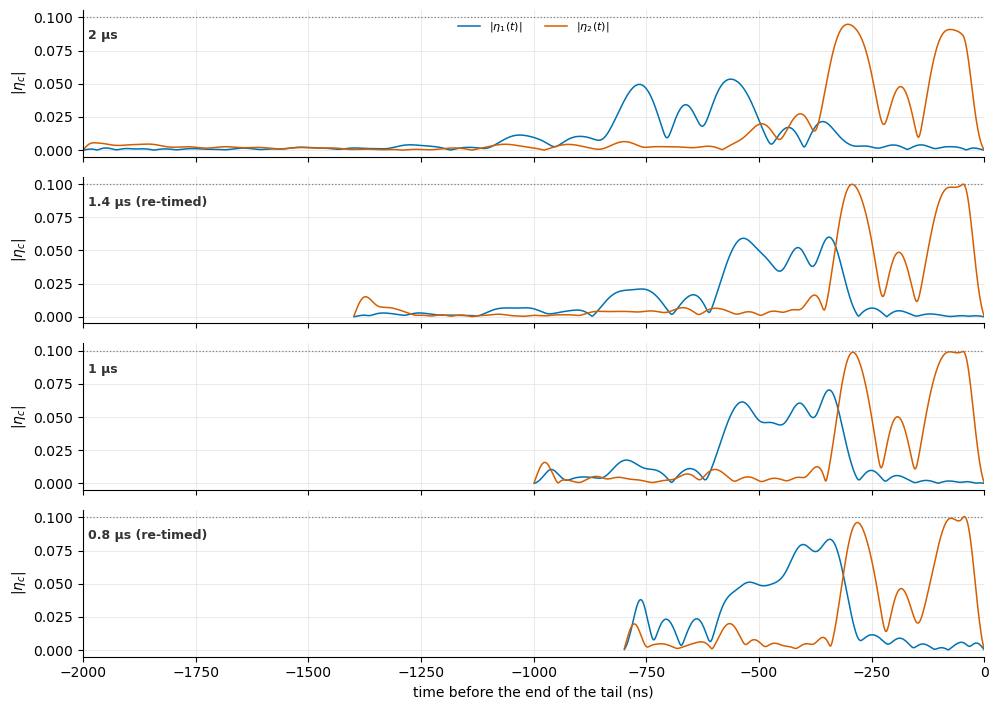

In [31]:
def rt_eta(T):
    return RT[T]["eta"] if T in RT_T else best_eta(T)


fig, axes = plt.subplots(len(ALL_T), 1, figsize=(10.0, 7.2), sharex=True, sharey=True)
for ax, T in zip(axes, ALL_T[::-1]):
    eta = rt_eta(T)
    t_end = ((np.arange(len(eta)) + 0.5) * DT - T) * 1e3            # ns, counted back from the end of the tail
    for c, col in ((0, OKABE[0]), (1, OKABE[4])):
        ax.plot(t_end, np.abs(eta[:, c]), color=col, lw=1.1, label=fr"$|\eta_{c + 1}(t)|$")
    ax.axhline(ft.ETA_CAP, color="0.5", ls=":", lw=0.9)
    ax.text(0.005, 0.8, f"{T:g} μs" + (" (re-timed)" if T in RT_T else ""), transform=ax.transAxes,
            fontsize=9, color="0.2", fontweight="bold")
    ax.set_ylabel(r"$|\eta_c|$")
    tidy(ax)
axes[0].legend(fontsize=8, frameon=False, loc="upper center", ncol=2)
axes[-1].set_xlabel("time before the end of the tail (ns)")
axes[-1].set_xlim(-2000, 0)
fig.tight_layout()
fig.savefig("figures/fwm_tails_retimed_waveforms.png", dpi=150)
plt.show()

**Figure 11. The trained waveforms aligned at the end of the tail,** for the four EsT tails (top: 2 μs, bottom:
0.8 μs). Blue: $|\eta_1(t)|$ (comb 1); vermilion: $|\eta_2(t)|$ (comb 2); dotted: the cap 0.1.
*Symbols:* time is counted back from the end of each tail, so the shots line up on the right.

**What it shows.** All four tails end in the same shot: comb 1 from about 600 to 320 ns before the end, then comb 2
near the cap in two lobes, at about 300 and 60 ns before the end. The shot's length does not change with the tail
length. In the 0.8 μs tail only 200 ns of weak tones come before the shot, and its comb 1 is stronger (peak 0.083,
against 0.070 at 1 μs and 0.054–0.060 at 1.4 and 2 μs).

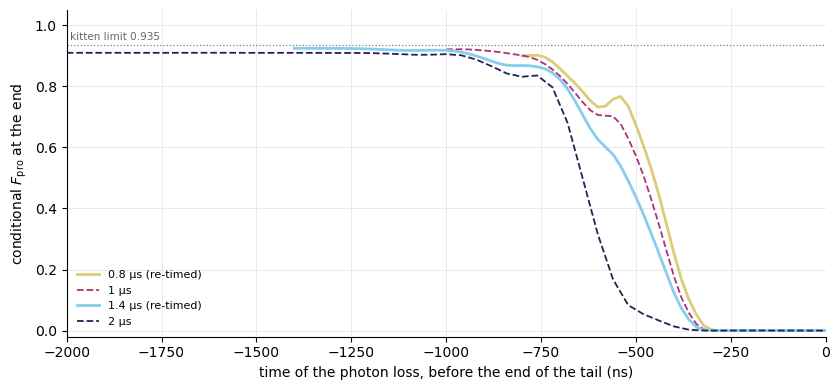

0.8 μs tail: a loss at the start is repaired to 0.899; below half of that from 440 ns before the end; unrepaired window 456 ns, costing about 0.91%
1 μs tail: a loss at the start is repaired to 0.921; below half of that from 460 ns before the end; unrepaired window 492 ns, costing about 1.00%
1.4 μs tail: a loss at the start is repaired to 0.924; below half of that from 500 ns before the end; unrepaired window 533 ns, costing about 1.09%
2 μs tail: a loss at the start is repaired to 0.910; below half of that from 600 ns before the end; unrepaired window 618 ns, costing about 1.24%


In [32]:
RT_SHOT_CSV = "tables/fwm_tail_shot_timing_retimed.csv"     # loss time for the re-timed tails, as §6.3
if not os.path.exists(RT_SHOT_CSV):
    from joblib import Parallel, delayed
    prof = Parallel(n_jobs=2)(delayed(loss_branch_profile)(RT[T]["eta"], 10) for T in RT_T)
    pd.DataFrame([{"test": "loss time", "tail_us": T, **r} for T, p in zip(RT_T, prof) for r in p]).to_csv(
        RT_SHOT_CSV, index=False)
LP_ALL = pd.concat([LP[LP.tail_us.isin((1.0, 2.0))], pd.read_csv(RT_SHOT_CSV)])

fig, ax = plt.subplots(figsize=(8.5, 4.0))
for T in ALL_T:
    g = LP_ALL[np.isclose(LP_ALL.tail_us, T)]
    ax.plot(g.t_ns - T * 1e3, g.f_branch, color=RT_COL[T], lw=2.0 if T in RT_T else 1.3,
            ls="-" if T in RT_T else "--", label=f"{T:g} μs" + (" (re-timed)" if T in RT_T else ""))
ax.axhline(F_KITTEN, color="0.5", ls=":", lw=0.9)
ax.text(-1990, F_KITTEN + 0.015, f"kitten limit {F_KITTEN:.3f}", fontsize=7.5, color="0.4")
ax.set_xlim(-2000, 0)
ax.set_ylim(-0.02, 1.05)
ax.set_xlabel("time of the photon loss, before the end of the tail (ns)")
ax.set_ylabel(r"conditional $F_{\rm pro}$ at the end")
ax.legend(fontsize=8, frameon=False, loc="lower left")
tidy(ax)
fig.tight_layout()
fig.savefig("figures/fwm_tails_retimed_loss_timing.png", dpi=150)
plt.show()

for T in ALL_T:
    g = LP_ALL[np.isclose(LP_ALL.tail_us, T)]
    f0, f = g.f_branch.iloc[0], g.f_branch.values
    step_us = np.diff(g.t_ns).mean() / 1e3
    unprot = np.sum(1 - f[:-1] / f0) * step_us
    t_half = T * 1e3 - g.t_ns.values[np.argmax(f < f0 / 2)]
    print(f"{T:g} μs tail: a loss at the start is repaired to {f0:.3f}; below half of that from {t_half:.0f} ns "
          f"before the end; unrepaired window {unprot * 1e3:.0f} ns, costing about {LOSS_RATE * f0 * unprot:.2%}")

**Figure 12. Which losses each tail repairs,** as Figure 8 (a, b): conditional $F_{\rm pro}$ at the end of the tail of
a branch with one photon loss at time $t$, gate and tail otherwise closed. Solid: the re-timed tails; dashed: the 1 μs
and 2 μs tails from §6.3.
*Symbols:* time of the loss counted back from the end of the tail; "unrepaired window" = time weighted by how badly a
loss there is repaired, $\int (1 - f(t)/f(0))\,dt$, as in §6.3; its cost is that window × 2.2 %/μs × $f(0)$.

**What it shows: a shorter tail repairs a little later, but repairs early losses a little worse.**

| tail | early loss repaired to | below half from (before the end) | unrepaired window | its cost |
|---|---|---|---|---|
| 0.8 μs | 0.899 | 440 ns | 456 ns | 0.91 % |
| 1 μs | 0.921 | 460 ns | 492 ns | 1.00 % |
| 1.4 μs | 0.924 | 500 ns | 533 ns | 1.09 % |
| 2 μs | 0.910 | 600 ns | 618 ns | 1.24 % |

- The stronger comb 1 of the 0.8 μs tail repairs losses closer to the end: its unrepaired window is 36 ns shorter
  than at 1 μs, worth about 0.09 %.
- In exchange, a loss at the very start is repaired only to 0.899 (1 μs: 0.921). The two effects nearly cancel, which
  is why the 0.8 μs tail gains only 0.03 % in Table 18.
- Every tail still leaves 450–620 ns, about 1 %, unrepaired at its end. That is the floor of §6.5, and re-timing does
  not touch it.

In [33]:
rt_label = {RT_TAG[0.8]: "EsT 0.8 μs (re-timed)", RT_TAG[1.4]: "EsT 1.4 μs (re-timed)",
            parent_run(0.8)["tag"]: "EsT 1 μs (§6.6)"}
piv_rt = (pd.concat([HELD_RT[HELD_RT.kind == "trained"], HELD[HELD.tag == parent_run(0.8)["tag"]]])
          .assign(run=lambda d: d.tag.map(rt_label))
          .pivot(index="condition", columns="run", values="gain_vs_alone").loc[conds, list(rt_label.values())])
display(piv_rt.rename(index=COND_LABEL).style.format("{:+.2%}")
        .set_caption("Table 19. Gain over the EsT gate alone under each held-out condition"))

go_rt = []
for T in RT_T:
    tr = HELD_RT[HELD_RT.tag == RT_TAG[T]].set_index("condition")
    gain = tr.loc["nc_b", "gain_vs_alone"]
    agree = abs(tr.loc["nc_a", "F_pro"] - tr.loc["nc_b", "F_pro"])
    cap = max(RT[T]["info"]["max_eta_1"], RT[T]["info"]["max_eta_2"])
    ok = (gain >= 0.003, agree <= 1e-4, cap <= 1.02 * ft.ETA_CAP)
    go_rt.append({"tail (us)": T, "gain at converged n_c": gain, "gain >= 0.3 %": ok[0],
                  "n_c agree to 1e-4": ok[1], "max |eta| <= 0.1": ok[2], "verdict": "GO" if all(ok) else "no-go"})
display(pd.DataFrame(go_rt).rename(columns=MU).style.hide(axis="index")
        .format({"tail (μs)": "{:g}", "gain at converged n_c": "{:+.2%}"})
        .set_caption("Table 20. Go / no-go for the re-timed EsT tails"))

run,EsT 0.8 μs (re-timed),EsT 1.4 μs (re-timed),EsT 1 μs (§6.6)
condition,,,
"training (n_c 16, cut)",+0.19%,+0.05%,+0.16%
"n_c 18 (d2) / 24 (EsT, Ord)",+0.19%,+0.05%,+0.16%
"n_c 20 (d2) / 28 (EsT, Ord)",+0.19%,+0.05%,+0.16%
n_r = 3,+0.18%,+0.05%,+0.16%
+ dephasing and heating,-0.03%,-0.31%,-0.11%
couplings g/√2,-11.51%,-4.15%,-6.71%
η × 0.9,-13.69%,-4.26%,-7.65%
η × 1.1,-16.99%,-5.18%,-9.62%
Stark shift off,-84.56%,-41.75%,-63.14%


tail (μs),gain at converged n_c,gain >= 0.3 %,n_c agree to 1e-4,max |eta| <= 0.1,verdict
0.8,+0.19%,False,True,True,no-go
1.4,+0.05%,False,True,True,no-go


**Table 19. Gain over the EsT gate alone under each held-out condition,** for the two re-timed tails and the 1 μs
tail of §6.6. **Table 20. Go / no-go,** the rule of Table 16.
*Symbols:* as Table 14; scored by `DGRAPE/fwm_tail_score.py` into `tables/fwm_tail_heldout_retimed.csv`, gains against
the gate alone scored under the same condition.

**What it shows.**

- **Neither tail passes.** 0.8 μs: +0.19 % at $n_c = 28$ ($n_c$ 24 and 28 agree), under the cap with 2 % allowed;
  short of the +0.3 % bar. 1.4 μs: +0.05 %.
- **With dephasing and heating** the 0.8 μs tail nearly breaks even (−0.03 %, against −0.11 % for the 1 μs tail and
  −0.31 % for 1.4 μs). A shorter tail spends less time exposed to the channels it was not trained on.
- **It is more fragile.** A 10 % pump error costs 13.7–17.0 % at 0.8 μs (1 μs: 7.7–9.6 %; 1.4 μs: 4.3–5.2 %), and
  turning off the Stark shift costs 85 %. The shorter tail packs the same repair into stronger, more finely tuned
  pulses, so it depends more on getting the pump strength and the Stark shift exactly right.
- **The cause stays the same as before.** Photon loss only: +0.62 % (1 μs: +0.57 %), closed: −0.01 %, all but photon
  loss: −0.26 %. The 0.8 μs tail repairs slightly more and is otherwise the 1 μs tail.

**Conclusion of §6.8.** Cutting the wait in front of the shot does not move the result: 0.8 μs gains +0.03 % over the
1 μs tail, at the cost of a tail twice as sensitive to the pump strength. The front was partly doing coherent work,
and the losses there were already repaired. What limits the tail is the shot itself (§6.5): its unrepaired end and
the transmon decay during it. A faster comb 2 is still the lever, not a shorter wait.

# 7. Conclusions and next steps

**What the campaign shows.**

1. **The gate decides.** The same tail shape gains +0.16 % after the EsT gate and loses 0.58 % and 0.67 % after Ord
   and d2. A gate whose losses stay clean error words is what makes a repair tail worth anything.
2. **An FWM tail does repair photon loss,** with one ~600 ns shot at the end of the tail, whatever the tail's
   length (0.8 to 2 μs, §6.8). The tail's own time, the part
   of the shot during which losses cannot be repaired, and transmon decay while population sits in $|f\rangle$ eat
   almost all of it (Table 13).
3. **The result is fragile and thinly supported.** A 10 % pump error costs about 8–10 %; with dephasing and heating,
   or with a readout that must end empty, the gain is gone. Each gate is a single training run and the +0.16 % has no
   error bar. The ranking of the gates is solid, because it follows their ideal-repair gains; the size of the gain is
   not.

**Next steps, roughly in order of cost.**

- **A faster shot,** above all a faster comb 2. The unrepaired end of the shot costs about 1.0 % (§6.3), six times the
  net gain, and is the largest single term in Table 13.
- **A shorter tail: done (§6.8).** 0.8 μs, started from the end of the 1 μs shot, gains +0.19 % over the gate
  alone, only +0.03 % over the 1 μs tail, and is twice as sensitive to the pump strength. The quiet front was
  partly cancelling the Kerr phase, and the losses there were already repaired. 1.4 μs: +0.05 %.
- **Robust training:** average the cost over pump scales of about ±5 %, as the fragility asks for.
- **A gate trained for repairable losses,** for example one trained against the ideal repair's adjoint targets,
  $\hat T_b \to \mathcal R^\dagger(\hat T_b)$ ($\mathcal R$ = the ideal repair), so that loss branches land where
  the repair expects them.

**Checklist.**

| # | check | status |
|---|---|---|
| 1 | The frame is exact: idle = DGRAPE idle; random $\eta$ = DGRAPE frame with CF4 | done (Appendix A; tests `Idle`, `Frame`) |
| 2 | Teeth land on their paths (offsets, a path-1 swap) | done (Table 7; test `Teeth`) |
| 3 | Exact gradient: W form = augmented = central differences | done (Appendix A; test `Gradient`) |
| 4 | Objective: pre-image gradient, cap penalty, 3 jobs = 1 job | done (test `Objective`) |
| 5 | Input = the gate's output, propagated at $n_r = 2$ directly | done (test `Input`) |
| 6 | Upper limits: ideal repair, kitten limit, best recovery | done (§2; test `Ceilings`) |
| 7 | $n_r = 2$ against 3 | done for modest pumps (test `Readout`); trained tails in held-out scoring (§6.6) |
| 8 | Timing of one evaluation | done (Appendix A.2) |
| 9 | EsT gate on this chip: closed cost and gradient, frame = DGRAPE's, transparency measures | done (§3; `validation/test_est_gate.py`) |
| 10 | Training a tail | done (§6): 15 runs, 8 resumed; EsT + 1 μs +0.16 %, no-go for every gate and length |
| 11 | Re-timed EsT tails, 0.8 and 1.4 μs | done (§6.8): +0.19 % and +0.05 %, no-go |

**Open decisions.**

| decision | options | current choice |
|---|---|---|
| the gate | d2 / EsT / a gate trained for repairable losses | EsT; the gain follows how repairable the gate leaves its losses |
| tail length | 0.5 – 3 μs | 0.8–1 μs (EsT 0.8 μs +0.19 %, 1 μs +0.16 %; 0.8 μs is more fragile); 0.5 μs is too short for the ~600 ns shot |
| controls | combs / combs + cavity drive | combs; the cavity drive keeps the frame exact and is the next knob |
| cap | per comb / on $\lvert\eta_1\rvert^2 + \lvert\eta_2\rvert^2$ | 0.1 per comb |
| readout at the end | traced / must be empty | traced; "empty" reported (Table 15) |

# Appendix A. Checks and cost

## A.1 Checks of the propagator and the gradient

Each check compares the tail propagator with something it does not use itself. `validation/test_fwm_tail.py` runs
smaller versions of all three.

1. **No pumps = DGRAPE's idle evolution.** With $\eta = 0$, the tail (rotated frame) and `lnp.propagate` (DGRAPE frame)
   must give the same $F_{\rm pro}$ and the same transmon-$g$ block.
2. **The frame is exact.** A random piecewise-constant $\eta$, with the Stark and pump-mixing terms on, is compared
   with `fwm.propagate` in the DGRAPE frame, which uses explicit carriers $(+\Delta_{\rm ref}, -\Delta_{\rm ref})$ and
   CF4 sub-steps (a fourth-order method with several exponentials per step). CF4 must converge to the tail's single
   exponential at fourth order.
3. **The gradient.** The W-form gradient (the exact adjoint gradient of `fwm.py`) is compared with the
   augmented-generator derivative (a second exact method, which differentiates the exponential through a doubled
   matrix) and with central finite differences.

In [29]:
# Check 1: eta = 0 for 0.5 us at n_c = 16
N05 = ft.n_steps(0.5)
R0 = ft.d2_output(N_C, 2)
R_tail, _ = ft.propagate(tm16, np.zeros((N05, 2)), R0)
R_dg = lnp.propagate(fwm.model_with_channels(N_C, 2, None, True), np.zeros((N05, 4)), R0, DT)
g_idx = (np.arange(tm16.model.d) // 2) % 3 == G
for readout in ("traced", "empty"):
    T_, w_ = ft.tail_targets(N_C, 2, readout=readout)
    print(f"readout {readout:6s}: F tail {ft.fidelity_from_outputs(R_tail, T_, w_):.12f}, "
          f"F DGRAPE {ft.fidelity_from_outputs(R_dg, T_, w_):.12f}")
print(f"largest difference in the transmon-g block: {np.abs(R_tail[:, g_idx][:, :, g_idx] - R_dg[:, g_idx][:, :, g_idx]).max():.1e}")

readout traced: F tail 0.943625106382, F DGRAPE 0.943625106382
readout empty : F tail 0.943625106382, F DGRAPE 0.943625106382
largest difference in the transmon-g block: 2.4e-14


In [30]:
# Check 2: the frame against the DGRAPE frame with explicit carriers, n_c = 10, 0.1 us, strong random eta
n_c10, N_chk = 10, 50
rng = np.random.default_rng(0)
eta_chk = 0.05 * (rng.normal(size=(N_chk, 2)) + 1j * rng.normal(size=(N_chk, 2)))
tm10 = ft.tail_model(n_c10, 2, mixing=1.0)
R0_10 = ft.d2_output(n_c10, 2)
R_f, spec_f = ft.propagate(tm10, eta_chk, R0_10)
m10 = Model(n_c10, 2, include_higher_order=True)
fw10 = fwm.fwm_terms(m10, 1.0, paths=(ft.N_REF,))
fw10.Delta = np.array([tm10.delta_ref, -tm10.delta_ref])
ph = np.exp(1j * tm10.delta_ref * N_chk * DT * np.real(np.diag(operators(n_c10, 2)["Pf"])))
R_f_dg = ph[:, None] * R_f * ph[None, :].conj()            # back to the DGRAPE frame
T10, w10 = ft.tail_targets(n_c10, 2)
rows = []
for S in (2, 4, 8, 16):
    R_d, spec_d = fwm.propagate(m10, fw10, np.zeros((N_chk, 4)), eta_chk, DT, S, R0_10)
    rows.append({"CF4 sub-steps S": S, "max |rho_DGRAPE - rho_tail|": np.abs(R_d - R_f_dg).max(),
                 "F_DGRAPE - F_tail": ft.fidelity_from_outputs(R_d, T10, w10) - ft.fidelity_from_outputs(R_f, T10, w10),
                 "Taylor (s, m) per exponential": str(spec_d)})
display(pd.DataFrame(rows).style.hide(axis="index")
        .format({"max |rho_DGRAPE - rho_tail|": "{:.1e}", "F_DGRAPE - F_tail": "{:+.1e}"})
        .set_caption(f"Table A1. One exponential per step (Taylor {spec_f}) against CF4 in the DGRAPE frame"))

CF4 sub-steps S,max |rho_DGRAPE - rho_tail|,F_DGRAPE - F_tail,"Taylor (s, m) per exponential"
2,5.0e-05,+2.3e-05,"(1, 15)"
4,3.2e-06,+1.4e-06,"(1, 12)"
8,2.0e-07,+9.0e-08,"(1, 10)"
16,1.2e-08,+5.6e-09,"(1, 8)"


**Table A1. One exponential per step against CF4 in the DGRAPE frame** ($n_c = 10$, 0.1 μs, random $|\eta|$ up to
0.12, Stark and mixing on).
*Symbols:* $S$ = CF4 sub-steps per 2 ns step; $\rho$ = the output density matrices; Taylor $(s, m)$ = scaling steps and
series terms per exponential.

In [31]:
# Check 3: the exact gradient, n_c = 8, 20 steps
tm8 = ft.tail_model(8, 2, mixing=1.0)
R0_8 = ft.d2_output(8, 2)
T8, w8 = ft.tail_targets(8, 2)
rng = np.random.default_rng(1)
eta8 = 0.05 * (rng.normal(size=(20, 2)) + 1j * rng.normal(size=(20, 2)))
deta = rng.normal(size=(20, 2)) + 1j * rng.normal(size=(20, 2))
F8, g8 = ft.fidelity_and_grad(tm8, eta8, R0_8, T8, w8)
w_form = np.sum(g8 * fwm.real_from_beta(deta))
aug = ft.directional_derivative(tm8, eta8, R0_8, T8, w8, deta)
h = 1e-6
fd = (ft.fidelity(tm8, eta8 + h * deta, R0_8, T8, w8) - ft.fidelity(tm8, eta8 - h * deta, R0_8, T8, w8)) / (2 * h)
print(f"W form {w_form:+.15f}\naugmented {aug:+.15f}   (relative difference {abs(w_form - aug) / abs(aug):.1e})\n"
      f"central differences {fd:+.12f}   (relative difference {abs(w_form - fd) / abs(fd):.1e})")

W form -0.035802026860084
augmented -0.035802026860084   (relative difference 5.8e-16)
central differences -0.035802026899   (relative difference 1.1e-09)


**Reading the checks.**

- **Check 1:** with no pumps, the tail and DGRAPE agree to round-off, with the readout traced or required empty.
- **Check 2 (Table A1):** CF4 in the DGRAPE frame converges to the tail's answer, 16 times closer per doubling of $S$,
  the fourth-order rate. So the single exponential per step is the exact solution of the same equation.
- **Check 3:** the W-form gradient equals the augmented-generator derivative to round-off (about $10^{-15}$
  relative), and central differences to about $10^{-9}$.

## A.2 Cost of one evaluation

One evaluation of the training cost (fidelity and exact gradient, the three process inputs as three parallel jobs) at
$n_c = 16$, for the default 1 μs tail after d2. Nothing is optimized.

In [32]:
obj = ft.TailObjective(tail_us=ft.TAIL_US, n_c=N_C, n_jobs=3)
try:
    x_t2 = ft.eta_preimage(lib["tableII"])
    obj.evaluate(np.zeros_like(x_t2) + 1e-9)                # warm up the workers (model build)
    t0 = time.time()
    cost_t2, g_t2, terms_t2 = obj.evaluate(x_t2)
    t_eval = time.time() - t0
finally:
    obj.close()
spec_tail = fwm.spec_for(tm16.model, tm16.fw, np.zeros((1, 4)), np.full((1, 2), 0.1), DT, 1, "midpoint")
m16 = Model(N_C, 2, include_higher_order=True)
fw16 = fwm.fwm_terms(m16)
spec_cf4 = fwm.spec_for(m16, fw16, np.zeros((1, 4)), np.array([[0.1, 0, 0, 0.1, 0, 0]]), DT, 2, "cf4")
print(f"one evaluation, {ft.TAIL_US:g} μs tail, n_c = {N_C}, 3 jobs: {t_eval:.1f} s   (F_pro {terms_t2['F_pro']:.5f})")
print(f"Taylor (s, m) at the cap: tail {spec_tail}, one exponential per step; "
      f"fwm_grape CF4 S = 2: {spec_cf4}, four per step")

one evaluation, 1 μs tail, n_c = 16, 3 jobs: 4.2 s   (F_pro 0.92824)
Taylor (s, m) at the cap: tail (1, 18), one exponential per step; fwm_grape CF4 S = 2: (1, 15), four per step


**Reading.** One evaluation of the 1 μs tail (500 steps) takes about 4 s on this Mac, with 3 jobs and nothing else
running. The cost grows linearly with the tail length and steeply with $n_c$. A 300-iteration d2 run (about 1.06
evaluations per iteration) is therefore about 20 minutes on its own. The training runs were slower: on the Windows PC,
four side by side, one 1 μs evaluation took about 27 s (Appendix B.2).

For comparison, one 1.1 μs Stage 2 evaluation in `fwm_grape` took 48–62 s (on another machine). The saving is in the
number of exponentials, not their length. One exponential covers the whole 2 ns step, so its Taylor series is slightly
longer than one CF4 exponential's (18 terms against 15), but there is one per step instead of four (18 terms per step
against 60).

# Appendix B. Decisions, run logistics, a second EsT sample

## B.1 Decisions

| item | choice | date |
|---|---|---|
| input to the tail | the mixed output state of a gate: d2 in §2 and §4; for training, EsT, Ord and d2 | 2026-10-19; EsT and Ord 2026-10-20 |
| baseline | **the same gate alone**, scored at the end of the gate (d2: $F_{\rm pro} = 0.955554$ at $n_c = 16$) | 2026-10-19 |
| controls | the two combs only; the cavity drive may be added later | 2026-10-19 |
| strength cap | $\lvert\eta_c(t)\rvert = \lvert\xi_c(t)\rvert \le 0.1$ for each comb (§4.1) | 2026-10-19 |
| readout | readout decay in the model; the readout is **traced out** at the end; $\langle\hat n_r\rangle$ at the end is reported | 2026-10-19 |
| tail length | **1 μs** by default, a parameter (3 μs until 2026-10-20, see §2.4); baselines also at 0.5, 2 and 3 μs | 2026-10-20 |
| free rotation | **none**: the target is the ideal X. The storage Kerr phase and the tail's own Stark rotation are errors the tail must cancel | 2026-10-19 |
| EsT gate (§3) | EST's cost and two-stage weights, 2000 iterations per stage, closed system, with d2's chip, code, duration, drive limits and start; scored in the open system | 2026-10-20 |
| control for it | an Ord gate trained the same way with the transparency terms off | 2026-10-20 |
| tails in §3 | upper limits and fixed tails only (ideal repair, best recovery, idle, Table II teeth) | 2026-10-20 |
| tail training (§5, §6) | EsT, Ord and d2; 0.5, 1, 2 μs; starts Table II and zero + noise (d2: Table II only); the tail at $n_c = 16$ on the gate output propagated at $n_c = 24$ and cut (≤ 2 × 10⁻⁵ lost) | 2026-10-21 |
| re-timed tails (§6.8) | EsT only; 0.8 μs and 1.4 μs, started from the last 0.8 μs of the 1 μs tail and the last 1.4 μs of the 2 μs tail (pre-images cut); 600 iterations in one leg. Prediction recorded before training: up to +0.18 % over the 1 μs tail (≈ +0.3 % over the gate alone) and up to +0.5 % over the 2 μs tail, from §6.3's slide slope. Revised after the crop check (Table 17), still before training: ≈ +0.28 % and ≈ 0 % over the gate alone. Result: +0.19 % and +0.05 % | 2026-10-26 |
| truncation | $n_c = 16$ for d2; $n_c = 24$ (held out: 28) for anything with a closed-trained gate, which reaches photon number 15–17 | 2026-10-20 |

## B.2 Run logistics

- **Machine.** The tails were trained on the Windows PC. numpy there uses OpenBLAS, so the scripts'
  `MKL_NUM_THREADS=1` does nothing, and each joblib worker took 8 threads. The runs were launched with
  `OPENBLAS_NUM_THREADS=2`, which cut one 1 μs evaluation from 31 s to 12 s with a run alone on the machine.
- **First leg.** Four runs side by side (`xargs -P 4`, longest first), which roughly doubles the time per evaluation:
  about 11 s (0.5 μs), 27 s (1 μs) and 50–56 s (2 μs), with about 1.06 evaluations per iteration. The 15 runs took
  10.4 h (2026-10-21, 02:14 to 12:37).
- **Resumed leg.** The eight resumed runs, four side by side, took 8.1 h (2026-10-21 20:53 to 2026-10-22 04:57).
- **Total per run.** About 5 h for a 1 μs tail (600 iterations) and 11 h for a 2 μs tail (Table 10, "hours").
- **Re-timed tails (§6.8).** Two runs side by side, 600 iterations each, in `~/fwm_runs/tails_rt` (2026-10-26):
  0.8 μs 2.9 h (about 16 s per iteration), 1.4 μs 4.2 h (about 25 s, faster once alone). Held-out scoring
  (`DGRAPE/fwm_tail_score.py`, 12 jobs) took about 5 min.

## B.3 A second sample of the EsT training (seed 43)

The same EsT training from seed 43, scored as in Table 5, to see whether seed 42's numbers are typical.

In [33]:
# A second sample of the same EsT training (seed 43)
u43 = np.load("pulses/dgrape/u_X_est_closed_s43.npy")
R43 = ft.gate_output(u43, N_CMP, 1)
F43 = ft.fidelity_from_outputs(R43, T24, W24)
rep43 = ft.ideal_repair_fidelity(R43, T24, W24, N_CMP, 1)
ph43 = ft.ideal_repair_fidelity(ft.gate_output(u43, N_CMP, 1, {"a"}), T24, W24, N_CMP, 1)["phases"]
pr43 = ft.loss_time_profile(ph43, N_CMP, pulse=u43)
s43 = eg.summary(eg.metrics(u43, N_CMP))
print(f"EsT at seed 43: F_pro {F43:.5f}, + ideal repair {rep43['F']:.5f} ({rep43['F'] - F43:+.4f}); a loss during the "
      f"gate after the ideal repair {np.sum(pr43['p'] * pr43['f_repaired']) / pr43['p'].sum():.3f}; "
      f"mean L {s43['leakage_mean']:.3f}, L at the end {s43['leakage_T']:.3f}")

EsT at seed 43: F_pro 0.96660, + ideal repair 0.98625 (+0.0196); a loss during the gate after the ideal repair 0.839; mean L 0.223, L at the end 0.138


**Reading.** Seed 43 agrees with seed 42: $F_{\rm pro}$ 0.96660 alone, an ideal-repair gain of +1.96 % (seed 42:
+1.85 %), and a repaired loss scores 0.839 on average (0.861). Its transparency is similar (mean $L$ 0.22, $L$ at
$T_g$ 0.14).